<a href="https://colab.research.google.com/github/Ansarss/Ai_learning_experiments/blob/main/Credit_Risk_Assessment_Model_Performance_and_Error_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ranadeep/credit-risk-dataset")

print("Path to dataset files:", path)

100%|██████████| 101M/101M [00:00<00:00, 134MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ranadeep/credit-risk-dataset/versions/3


# Credit Risk Assessment: Model Performance and Error Analysis

## Objective

This research project aims to develop a robust credit risk
classification model to predict loan default risk using
comprehensive cross-validation, error analysis, resampling
techniques, and bootstrap analysis.

## Step 1: Data Collection

The dataset is obtained from Kaggle and contains historical
loan and credit risk information.

Dataset Source:
https://www.kaggle.com/datasets/ranadeep/credit-risk-dataset

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 150)

In [3]:
# List all downloaded dataset files

for root, dirs, files in os.walk(path):
    for file in files:
        file_path = os.path.join(root, file)
        file_size = os.path.getsize(file_path) / (1024 ** 2)

        print(f"File Name: {file}")
        print(f"File Size: {file_size:.2f} MB")
        print(f"File Path: {file_path}")
        print("-" * 60)

File Name: LCDataDictionary.xlsx
File Size: 0.02 MB
File Path: /root/.cache/kagglehub/datasets/ranadeep/credit-risk-dataset/versions/3/LCDataDictionary.xlsx
------------------------------------------------------------
File Name: loan.csv
File Size: 421.31 MB
File Path: /root/.cache/kagglehub/datasets/ranadeep/credit-risk-dataset/versions/3/loan/loan.csv
------------------------------------------------------------


In [4]:
# Load the credit risk dataset

loan_path = os.path.join(path, "loan", "loan.csv")

df = pd.read_csv(loan_path, low_memory=False)

print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of features:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of records: 887379
Number of features: 74


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,1077501,1296599,5000.0,5000.0,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-1985,1.0,NaN,NaN,3.0,0.0,13648.0,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,Jan-2015,171.62,NaN,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,1314167,2500.0,2500.0,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-2011,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-1999,5.0,NaN,NaN,3.0,0.0,1687.0,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-2013,119.66,NaN,Sep-2013,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,1313524,2400.0,2400.0,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-2001,2.0,NaN,NaN,2.0,0.0,2956.0,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,Jun-2014,649.91,NaN,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1076863,1277178,10000.0,10000.0,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0.0,Feb-1996,1.0,35.0,NaN,10.0,0.0,5598.0,21.0,37.0,f,0.0,0.0,12226.302212,12226.30,10000.00,2209.33,16.97,0.00,0.00,Jan-2015,357.48,NaN,Jan-2015,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1075358,1311748,3000.0,3000.0,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,RENT,80000.0,Source Verified,Dec-2011,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > I plan on combi...,other,Personal,972xx,OR,17.94,0.0,Jan-1996,0.0,38.0,NaN,15.0,0.0,27783.0,53.9,38.0,f,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,Jan-2016,67.79,Feb-2016,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Inspect dataset columns and data types

df.info()

# List all column names

print("\nDataset Columns:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887379 entries, 0 to 887378
Data columns (total 74 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           887379 non-null  int64  
 1   member_id                    887379 non-null  int64  
 2   loan_amnt                    887379 non-null  float64
 3   funded_amnt                  887379 non-null  float64
 4   funded_amnt_inv              887379 non-null  float64
 5   term                         887379 non-null  object 
 6   int_rate                     887379 non-null  float64
 7   installment                  887379 non-null  float64
 8   grade                        887379 non-null  object 
 9   sub_grade                    887379 non-null  object 
 10  emp_title                    835917 non-null  object 
 11  emp_length                   842554 non-null  object 
 12  home_ownership               887379 non-null  object 
 13 

,Count,Percentage (%)
loan_status,,
Current,601779,67.815330
Fully Paid,207723,23.408600
Charged Off,45248,5.099061
Late (31-120 days),11591,1.306206
Issued,8460,0.953369
In Grace Period,6253,0.704659
Late (16-30 days),2357,0.265614
Does not meet the credit policy. Status:Fully Paid,1988,0.224031
Default,1219,0.137371


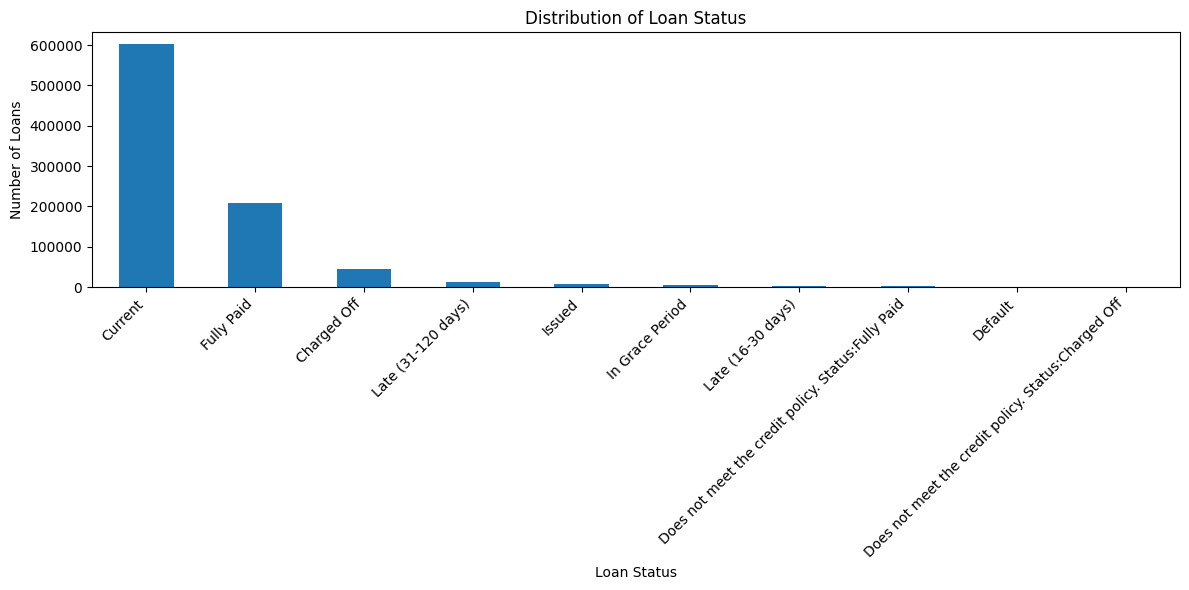

In [6]:
# Examine loan status distribution

if 'loan_status' in df.columns:
    status_summary = pd.DataFrame({
        'Count': df['loan_status'].value_counts(),
        'Percentage (%)': df['loan_status'].value_counts(
            normalize=True
        ) * 100
    })

    display(status_summary)

    plt.figure(figsize=(12, 6))
    df['loan_status'].value_counts().plot(kind='bar')
    plt.title('Distribution of Loan Status')
    plt.xlabel('Loan Status')
    plt.ylabel('Number of Loans')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Target variable needs to be identified.")

In [7]:
# Missing value analysis

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage (%)',
    ascending=False
)

display(missing_summary[missing_summary['Missing Count'] > 0])

# Check duplicate records

print("Duplicate records:", df.duplicated().sum())

,Missing Count,Missing Percentage (%)
dti_joint,886870,99.942640
annual_inc_joint,886868,99.942415
verification_status_joint,886868,99.942415
il_util,868762,97.902024
mths_since_rcnt_il,866569,97.654892
inq_fi,866007,97.591559
open_rv_24m,866007,97.591559
open_acc_6m,866007,97.591559
all_util,866007,97.591559
inq_last_12m,866007,97.591559


Duplicate records: 0


In [8]:
# Load the data dictionary

dictionary_path = os.path.join(
    path, "LCDataDictionary.xlsx"
)

dictionary = pd.ExcelFile(dictionary_path)

print("Available sheets:", dictionary.sheet_names)

data_dictionary = pd.read_excel(
    dictionary_path,
    sheet_name=0
)

display(data_dictionary.head(20))

Available sheets: ['LoanStats', 'browseNotes', 'RejectStats']


,LoanStatNew,Description
0,addr_state,The state provided by the borrower in the loan...
1,annual_inc,The self-reported annual income provided by th...
2,annual_inc_joint,The combined self-reported annual income provi...
3,application_type,Indicates whether the loan is an individual ap...
4,collection_recovery_fee,post charge off collection fee
5,collections_12_mths_ex_med,Number of collections in 12 months excluding m...
6,delinq_2yrs,The number of 30+ days past-due incidences of ...
7,desc,Loan description provided by the borrower
8,dti,A ratio calculated using the borrower’s total ...
9,dti_joint,A ratio calculated using the co-borrowers' tot...


## Step 2: Data Preprocessing

The original dataset contains 887,379 loan records and 74
columns. Initial data inspection identified significant class
imbalance, missing values, unresolved loan outcomes, and
potential target leakage.

The preprocessing strategy includes:

- Defining a binary loan default target.
- Excluding unresolved loan outcomes.
- Removing post-origination variables to prevent data leakage.
- Selecting relevant credit risk predictors.
- Handling missing values.
- Encoding categorical features.
- Scaling numerical variables.
- Creating independent training and testing datasets.

Learned preprocessing transformations will be fitted only
on training data to preserve the integrity of model evaluation.

In [9]:
# Define eligible loan outcomes

valid_statuses = [
    'Fully Paid',
    'Charged Off',
    'Default'
]

df_clean = df[df['loan_status'].isin(valid_statuses)].copy()

# Create binary target variable
df_clean['default'] = df_clean['loan_status'].map({
    'Fully Paid': 0,
    'Charged Off': 1,
    'Default': 1
})

df_clean['default'] = df_clean['default'].astype(int)

print("Original dataset:", df.shape)
print("Filtered dataset:", df_clean.shape)
print("Excluded records:", len(df) - len(df_clean))

target_summary = pd.DataFrame({
    'Count': df_clean['default'].value_counts(),
    'Percentage (%)': df_clean['default'].value_counts(
        normalize=True
    ) * 100
})

display(target_summary)

Original dataset: (887379, 74)
Filtered dataset: (254190, 75)
Excluded records: 633189


,Count,Percentage (%)
default,,
0,207723,81.71958
1,46467,18.28042


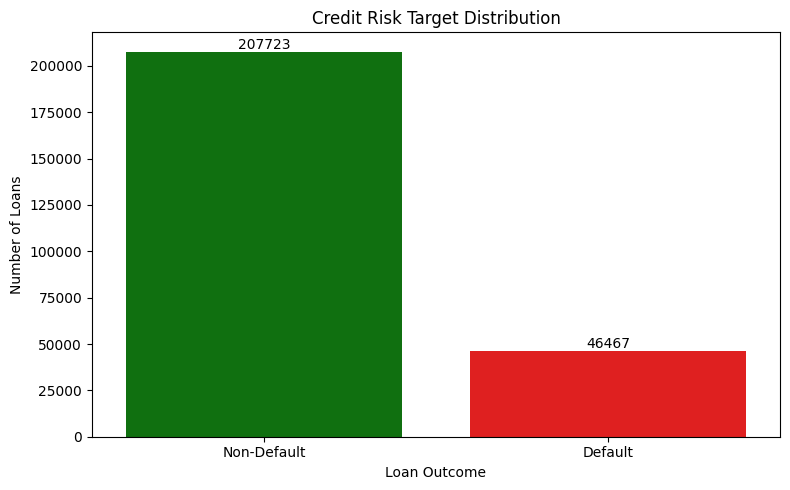

In [10]:
# Visualize the binary target distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x='default',
    hue='default',
    palette=['green', 'red'],
    legend=False
)

plt.title('Credit Risk Target Distribution')
plt.xlabel('Loan Outcome')
plt.ylabel('Number of Loans')

plt.xticks(
    [0, 1],
    ['Non-Default', 'Default']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

In [11]:
# Select candidate loan-origination predictors

selected_features = [
    'loan_amnt',
    'term',
    'int_rate',
    'installment',
    'grade',
    'sub_grade',
    'emp_length',
    'home_ownership',
    'annual_inc',
    'verification_status',
    'purpose',
    'dti',
    'delinq_2yrs',
    'earliest_cr_line',
    'inq_last_6mths',
    'mths_since_last_delinq',
    'mths_since_last_record',
    'open_acc',
    'pub_rec',
    'revol_bal',
    'revol_util',
    'total_acc',
    'collections_12_mths_ex_med',
    'acc_now_delinq',
    'tot_coll_amt',
    'tot_cur_bal',
    'total_rev_hi_lim',
    'issue_d',
    'member_id',
    'default'
]

df_model = df_clean[selected_features].copy()

print("Dataset before feature filtering:", df_clean.shape)
print("Dataset after feature filtering:", df_model.shape)

removed_columns = [
    col for col in df_clean.columns
    if col not in selected_features
]

print("\nExcluded columns:")

for col in removed_columns:
    print(col)

Dataset before feature filtering: (254190, 75)
Dataset after feature filtering: (254190, 30)

Excluded columns:
id
funded_amnt
funded_amnt_inv
emp_title
loan_status
pymnt_plan
url
desc
title
zip_code
addr_state
initial_list_status
out_prncp
out_prncp_inv
total_pymnt
total_pymnt_inv
total_rec_prncp
total_rec_int
total_rec_late_fee
recoveries
collection_recovery_fee
last_pymnt_d
last_pymnt_amnt
next_pymnt_d
last_credit_pull_d
mths_since_last_major_derog
policy_code
application_type
annual_inc_joint
dti_joint
verification_status_joint
open_acc_6m
open_il_6m
open_il_12m
open_il_24m
mths_since_rcnt_il
total_bal_il
il_util
open_rv_12m
open_rv_24m
max_bal_bc
all_util
inq_fi
total_cu_tl
inq_last_12m


In [12]:
# Missing values after feature filtering

missing_model = pd.DataFrame({
    'Missing Count': df_model.isnull().sum(),
    'Missing Percentage (%)': (
        df_model.isnull().mean() * 100
    )
})

missing_model = missing_model.sort_values(
    'Missing Percentage (%)',
    ascending=False
)

display(missing_model)

,Missing Count,Missing Percentage (%)
mths_since_last_record,222376,87.484165
mths_since_last_delinq,141446,55.645777
tot_cur_bal,63726,25.070223
tot_coll_amt,63726,25.070223
total_rev_hi_lim,63726,25.070223
emp_length,9968,3.921476
revol_util,200,0.078681
collections_12_mths_ex_med,56,0.022031
sub_grade,0,0.000000
loan_amnt,0,0.000000


In [13]:
# Convert loan issuance date

df_model['issue_d'] = pd.to_datetime(
    df_model['issue_d'],
    format='%b-%Y',
    errors='coerce'
)

print("Earliest loan issuance:",
      df_model['issue_d'].min())

print("Latest loan issuance:",
      df_model['issue_d'].max())

print("Missing issuance dates:",
      df_model['issue_d'].isna().sum())

print("Repeated borrower IDs:",
      df_model['member_id'].duplicated().sum())

# Annual loan distribution

annual_summary = df_model.groupby(
    df_model['issue_d'].dt.year
)['default'].agg(['count', 'sum', 'mean'])

annual_summary.columns = [
    'Total Loans',
    'Default Loans',
    'Default Rate'
]

annual_summary['Default Rate'] *= 100

display(annual_summary)

Earliest loan issuance: 2007-06-01 00:00:00
Latest loan issuance: 2015-12-01 00:00:00
Missing issuance dates: 0
Repeated borrower IDs: 0


,Total Loans,Default Loans,Default Rate
issue_d,,,
2007,251,45,17.928287
2008,1562,247,15.813060
2009,4716,594,12.595420
2010,11522,1484,12.879708
2011,19683,3213,16.323731
2012,49591,8112,16.357807
2013,71414,15018,21.029490
2014,69307,14594,21.057036
2015,26144,3160,12.086903


## Step 3: Feature Engineering and Feature Selection

Feature engineering transforms existing financial variables
into meaningful indicators of borrower creditworthiness.

The engineered features capture repayment burden, credit
history, revolving credit utilization, delinquency patterns,
and interactions between financial risk variables.

Three feature selection techniques will be evaluated:

1. Recursive Feature Elimination (RFE)
2. Mutual Information
3. LASSO-based regularization

All learned preprocessing and feature selection procedures
will be restricted to training data to prevent data leakage.

In [14]:
# Create a copy for feature engineering

df_engineered = df_model.copy()

# Convert loan term into numeric months
df_engineered['term'] = (
    df_engineered['term']
    .str.extract(r'(\d+)')[0]
    .astype(float)
)

# Convert earliest credit line into datetime
df_engineered['earliest_cr_line'] = pd.to_datetime(
    df_engineered['earliest_cr_line'],
    format='%b-%Y',
    errors='coerce'
)

# Credit history length in years
df_engineered['credit_history_years'] = (
    df_engineered['issue_d'] -
    df_engineered['earliest_cr_line']
).dt.days / 365.25

# Remove invalid negative credit ages
df_engineered.loc[
    df_engineered['credit_history_years'] < 0,
    'credit_history_years'
] = np.nan

# Loan-to-income ratio
df_engineered['loan_to_income'] = (
    df_engineered['loan_amnt'] /
    df_engineered['annual_inc'].replace(0, np.nan)
)

# Annual installment burden
df_engineered['installment_to_income'] = (
    df_engineered['installment'] * 12 /
    df_engineered['annual_inc'].replace(0, np.nan)
)

# Revolving credit utilization ratio
df_engineered['credit_utilization_ratio'] = (
    df_engineered['revol_bal'] /
    df_engineered['total_rev_hi_lim'].replace(0, np.nan)
)

# Proportion of open credit accounts
df_engineered['open_account_ratio'] = (
    df_engineered['open_acc'] /
    df_engineered['total_acc'].replace(0, np.nan)
)

# Historical delinquency indicator
df_engineered['has_recent_delinquency'] = (
    df_engineered['delinq_2yrs'] > 0
).astype(int)

# Public derogatory record indicator
df_engineered['has_public_record'] = (
    df_engineered['pub_rec'] > 0
).astype(int)

# Interaction between debt burden and interest rate
df_engineered['dti_interest_interaction'] = (
    df_engineered['dti'] *
    df_engineered['int_rate']
)

# Interaction between credit utilization and debt burden
df_engineered['utilization_dti_interaction'] = (
    df_engineered['revol_util'] *
    df_engineered['dti']
)

# Replace infinite values
df_engineered.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# Remove raw credit date after deriving credit age
df_engineered.drop(
    columns=['earliest_cr_line'],
    inplace=True
)

print("Original modeling dataset:", df_model.shape)
print("Engineered dataset:", df_engineered.shape)

new_features = [
    col for col in df_engineered.columns
    if col not in df_model.columns
]

print("\nNewly engineered features:")
for feature in new_features:
    print(feature)

display(df_engineered[new_features].head())

Original modeling dataset: (254190, 30)
Engineered dataset: (254190, 38)

Newly engineered features:
credit_history_years
loan_to_income
installment_to_income
credit_utilization_ratio
open_account_ratio
has_recent_delinquency
has_public_record
dti_interest_interaction
utilization_dti_interaction


,credit_history_years,loan_to_income,installment_to_income,credit_utilization_ratio,open_account_ratio,has_recent_delinquency,has_public_record,dti_interest_interaction,utilization_dti_interaction
0,26.913073,0.208333,0.081435,NaN,0.333333,0,0,294.4725,2314.305
1,12.668036,0.083333,0.023932,NaN,0.750000,0,0,15.2700,9.400
2,10.080767,0.195886,0.082595,NaN,0.200000,0,0,139.1712,858.920
3,15.830253,0.203252,0.082759,NaN,0.270270,0,0,269.8000,420.000
5,7.080082,0.138889,0.052153,NaN,0.750000,0,0,88.4800,316.960


In [15]:
# Sort observations chronologically
df_engineered = df_engineered.sort_values(
    'issue_d'
).reset_index(drop=True)

# Define chronological holdout
cutoff_date = pd.Timestamp('2015-01-01')

train_df = df_engineered[
    df_engineered['issue_d'] < cutoff_date
].copy()

test_df = df_engineered[
    df_engineered['issue_d'] >= cutoff_date
].copy()

# Exclude identifiers and validation metadata
exclude_features = [
    'default',
    'issue_d',
    'member_id'
]

X_train = train_df.drop(columns=exclude_features)
y_train = train_df['default']

X_test = test_df.drop(columns=exclude_features)
y_test = test_df['default']

train_dates = train_df['issue_d']

print("Training dataset:", X_train.shape)
print("Testing dataset:", X_test.shape)

print("\nTraining date range:")
print(train_df['issue_d'].min(),
      train_df['issue_d'].max())

print("\nTesting date range:")
print(test_df['issue_d'].min(),
      test_df['issue_d'].max())

split_summary = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'Records': [len(y_train), len(y_test)],
    'Defaults': [y_train.sum(), y_test.sum()],
    'Default Rate (%)': [
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary)

Training dataset: (228046, 35)
Testing dataset: (26144, 35)

Training date range:
2007-06-01 00:00:00 2014-12-01 00:00:00

Testing date range:
2015-01-01 00:00:00 2015-12-01 00:00:00


,Dataset,Records,Defaults,Default Rate (%)
0,Training,228046,43307,18.990467
1,Testing,26144,3160,12.086903


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

# Identify numerical and categorical variables

numeric_features = (
    X_train.select_dtypes(include=np.number)
    .columns.tolist()
)

categorical_features = (
    X_train.select_dtypes(exclude=np.number)
    .columns.tolist()
)

# Numerical preprocessing

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

# Categorical preprocessing

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine preprocessing transformations

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline,
     categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 29
Categorical features: 6

Numerical columns:
['loan_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'credit_history_years', 'loan_to_income', 'installment_to_income', 'credit_utilization_ratio', 'open_account_ratio', 'has_recent_delinquency', 'has_public_record', 'dti_interest_interaction', 'utilization_dti_interaction']

Categorical columns:
['grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose']


In [17]:
from sklearn.model_selection import train_test_split

X_exp, _, y_exp, _ = train_test_split(
    X_train,
    y_train,
    train_size=20000,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Experimental dataset:", X_exp.shape)

experimental_summary = pd.DataFrame({
    'Count': y_exp.value_counts(),
    'Percentage (%)': y_exp.value_counts(
        normalize=True
    ) * 100
})

display(experimental_summary)

Experimental dataset: (20000, 35)


,Count,Percentage (%)
default,,
0,16202,81.01
1,3798,18.99


### Feature Selection and Comparative Evaluation

Three feature selection techniques are implemented to identify
the most informative predictors of loan default:

- Recursive Feature Elimination (RFE)
- Mutual Information
- LASSO-based L1 Regularization

A Logistic Regression model without feature selection serves
as the baseline.

Each technique is evaluated using five-fold stratified
cross-validation. Preprocessing and feature selection are
performed independently within each training fold to prevent
data leakage.

Evaluation metrics include accuracy, precision, recall,
F1-score, ROC-AUC, and average precision.

In [18]:
from sklearn.base import clone
from sklearn.feature_selection import (
    RFE,
    SelectKBest,
    mutual_info_classif,
    SelectFromModel
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Baseline Logistic Regression
base_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

# Mutual information scoring function
def mi_score(X, y):
    discrete_mask = np.array([
        np.unique(X[:, i]).size <= 2
        for i in range(X.shape[1])
    ])

    return mutual_info_classif(
        X,
        y,
        discrete_features=discrete_mask,
        random_state=RANDOM_STATE
    )

# Define feature selection methods
feature_selectors = {
    'Baseline (All Features)': 'passthrough',

    'RFE': RFE(
        estimator=clone(base_model),
        n_features_to_select=20,
        step=0.2
    ),

    'Mutual Information': SelectKBest(
        score_func=mi_score,
        k=20
    ),

    'LASSO (L1)': SelectFromModel(
        LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=0.1,
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        threshold=1e-5
    )
}

print("Feature selection methods initialized.")

for method in feature_selectors:
    print(method)

Feature selection methods initialized.
Baseline (All Features)
RFE
Mutual Information
LASSO (L1)


In [19]:
# Define stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define evaluation metrics

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'Average_Precision': 'average_precision'
}

feature_selection_results = []
feature_pipelines = {}

for name, selector in feature_selectors.items():

    print(f"Evaluating: {name}")

    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('selector', selector),
        ('classifier', clone(base_model))
    ])

    scores = cross_validate(
        pipeline,
        X_exp,
        y_exp,
        cv=cv,
        scoring=scoring,
        n_jobs=2,
        error_score='raise'
    )

    result = {'Method': name}

    for metric in scoring:
        result[metric] = scores[
            f'test_{metric}'
        ].mean()

        result[f'{metric}_SD'] = scores[
            f'test_{metric}'
        ].std(ddof=1)

    result['Mean Fit Time'] = (
        scores['fit_time'].mean()
    )

    feature_selection_results.append(result)
    feature_pipelines[name] = pipeline

feature_results_df = pd.DataFrame(
    feature_selection_results
)

feature_results_df = feature_results_df.sort_values(
    'Average_Precision',
    ascending=False
)

display(feature_results_df.round(4))

Evaluating: Baseline (All Features)
Evaluating: RFE
Evaluating: Mutual Information
Evaluating: LASSO (L1)


,Method,Accuracy,Accuracy_SD,Precision,Precision_SD,Recall,Recall_SD,F1,F1_SD,ROC_AUC,ROC_AUC_SD,Average_Precision,Average_Precision_SD,Mean Fit Time
3,LASSO (L1),0.8107,0.0020,0.5134,0.0512,0.0574,0.0132,0.1030,0.0219,0.7046,0.0061,0.3555,0.0085,0.7092
0,Baseline (All Features),0.8103,0.0019,0.5049,0.0531,0.0592,0.0124,0.1057,0.0201,0.7030,0.0067,0.3510,0.0079,1.0773
2,Mutual Information,0.8111,0.0023,0.5257,0.0670,0.0453,0.0126,0.0832,0.0220,0.6993,0.0046,0.3502,0.0076,2.6540
1,RFE,0.8084,0.0019,0.4397,0.0810,0.0253,0.0068,0.0476,0.0123,0.6921,0.0046,0.3301,0.0047,2.5117


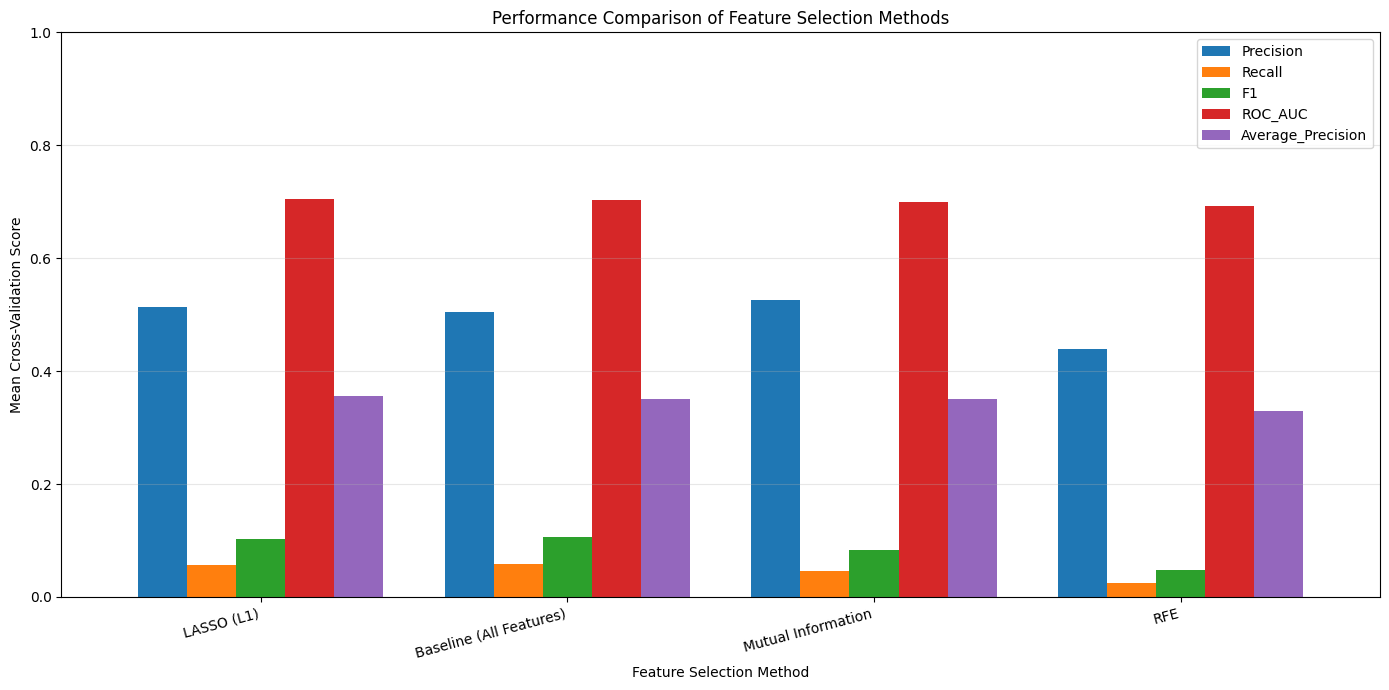

In [20]:
# Compare key performance metrics

comparison_metrics = [
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'Average_Precision'
]

feature_results_df.set_index('Method')[
    comparison_metrics
].plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title(
    'Performance Comparison of Feature Selection Methods'
)
plt.ylabel('Mean Cross-Validation Score')
plt.xlabel('Feature Selection Method')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
selected_feature_sets = {}
selection_summary = []

for name, pipeline in feature_pipelines.items():

    fitted_pipeline = clone(pipeline)
    fitted_pipeline.fit(X_exp, y_exp)

    feature_names = (
        fitted_pipeline
        .named_steps['preprocessor']
        .get_feature_names_out()
    )

    if name == 'Baseline (All Features)':
        selected_names = feature_names

    else:
        support = (
            fitted_pipeline
            .named_steps['selector']
            .get_support()
        )

        selected_names = feature_names[support]

    selected_feature_sets[name] = set(selected_names)

    selection_summary.append({
        'Method': name,
        'Original Transformed Features': len(feature_names),
        'Selected Features': len(selected_names),
        'Features Removed': (
            len(feature_names) - len(selected_names)
        )
    })

    print(f"\n{name}")
    print(f"Selected features: {len(selected_names)}")
    print("-" * 60)

    if name != 'Baseline (All Features)':
        for feature in selected_names:
            print(feature)

selection_summary_df = pd.DataFrame(selection_summary)

display(selection_summary_df)


Baseline (All Features)
Selected features: 114
------------------------------------------------------------

RFE
Selected features: 20
------------------------------------------------------------
numeric__int_rate
numeric__loan_to_income
categorical__grade_A
categorical__grade_E
categorical__sub_grade_A1
categorical__sub_grade_B2
categorical__sub_grade_D4
categorical__sub_grade_F5
categorical__sub_grade_G1
categorical__sub_grade_G2
categorical__sub_grade_G4
categorical__sub_grade_G5
categorical__emp_length_Unknown
categorical__home_ownership_MORTGAGE
categorical__home_ownership_OWN
categorical__purpose_car
categorical__purpose_major_purchase
categorical__purpose_moving
categorical__purpose_small_business
categorical__purpose_vacation

Mutual Information
Selected features: 20
------------------------------------------------------------
numeric__loan_amnt
numeric__term
numeric__int_rate
numeric__installment
numeric__annual_inc
numeric__dti
numeric__delinq_2yrs
numeric__inq_last_6mths
nu

,Method,Original Transformed Features,Selected Features,Features Removed
0,Baseline (All Features),114,114,0
1,RFE,114,20,94
2,Mutual Information,114,20,94
3,LASSO (L1),114,56,58


,Feature,Methods Selecting Feature
12,categorical__grade_A,3
5,categorical__grade_E,3
10,numeric__int_rate,3
7,numeric__loan_to_income,3
6,categorical__emp_length_Unknown,2
31,categorical__grade_B,2
11,categorical__home_ownership_MORTGAGE,2
9,categorical__home_ownership_OWN,2
1,categorical__purpose_car,2
3,categorical__purpose_major_purchase,2


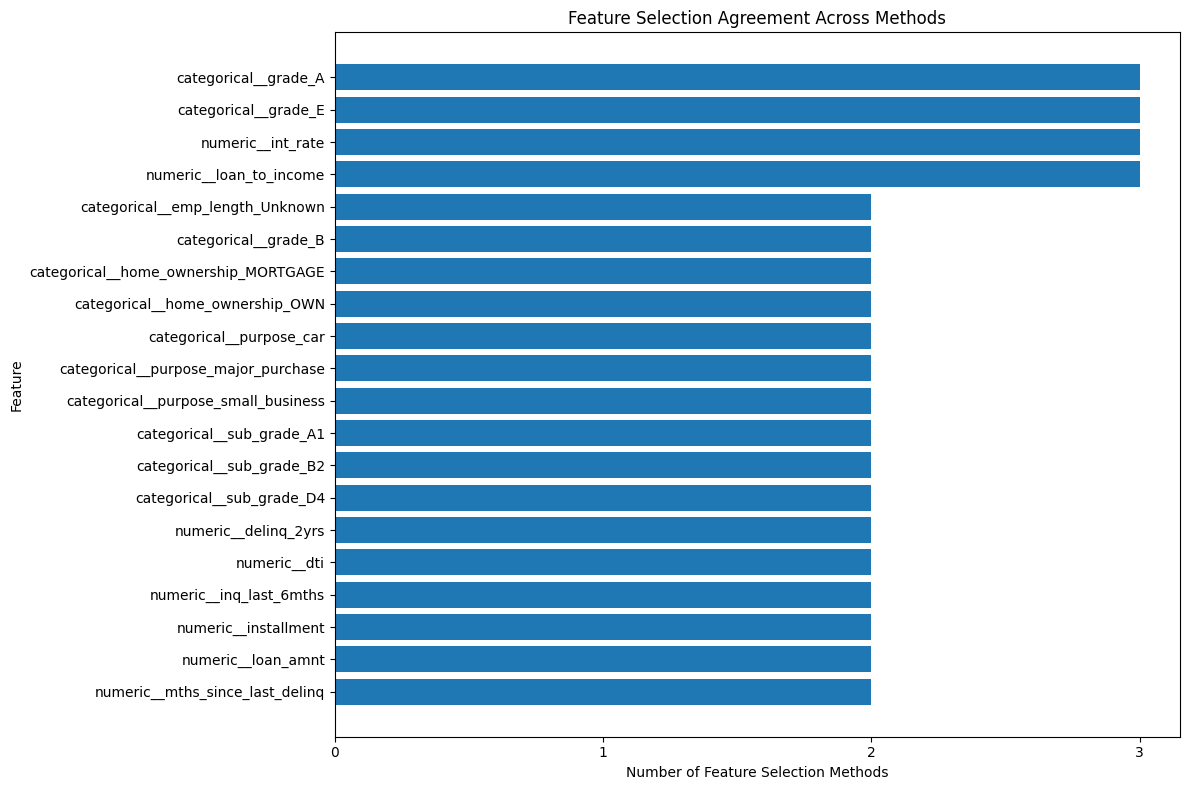

In [22]:
from collections import Counter

feature_frequency = Counter()

for method, features in selected_feature_sets.items():

    if method != 'Baseline (All Features)':
        feature_frequency.update(features)

consensus_df = pd.DataFrame(
    feature_frequency.items(),
    columns=['Feature', 'Methods Selecting Feature']
)

consensus_df = consensus_df.sort_values(
    ['Methods Selecting Feature', 'Feature'],
    ascending=[False, True]
)

display(consensus_df)

# Visualize most consistently selected features

top_features = consensus_df.head(20)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features['Feature'],
    top_features['Methods Selecting Feature']
)

plt.xlabel('Number of Feature Selection Methods')
plt.ylabel('Feature')
plt.title('Feature Selection Agreement Across Methods')
plt.xticks([0, 1, 2, 3])
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [23]:
from sklearn.preprocessing import TargetEncoder

preprocessing_results = []

for imputation in ['median', 'mean']:

    for encoding in ['One-Hot', 'Target']:

        numeric_alt = Pipeline([
            ('imputer', SimpleImputer(
                strategy=imputation,
                add_indicator=True
            )),
            ('scaler', StandardScaler())
        ])

        if encoding == 'One-Hot':
            encoder = OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            )

        else:
            encoder = TargetEncoder(
                target_type='binary',
                cv=5,
                random_state=RANDOM_STATE
            )

        categorical_alt = Pipeline([
            ('imputer', SimpleImputer(
                strategy='constant',
                fill_value='Unknown'
            )),
            ('encoder', encoder)
        ])

        alternative_preprocessor = ColumnTransformer([
            ('numeric', numeric_alt, numeric_features),
            ('categorical', categorical_alt,
             categorical_features)
        ])

        alternative_pipeline = Pipeline([
            ('preprocessor', alternative_preprocessor),
            ('classifier', clone(base_model))
        ])

        scores = cross_validate(
            alternative_pipeline,
            X_exp,
            y_exp,
            cv=cv,
            scoring=scoring,
            n_jobs=2,
            error_score='raise'
        )

        result = {
            'Imputation': imputation,
            'Encoding': encoding
        }

        for metric in scoring:
            result[metric] = scores[
                f'test_{metric}'
            ].mean()

        preprocessing_results.append(result)

preprocessing_results_df = pd.DataFrame(
    preprocessing_results
)

display(
    preprocessing_results_df.sort_values(
        'Average_Precision',
        ascending=False
    ).round(4)
)

,Imputation,Encoding,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
2,mean,One-Hot,0.8104,0.5082,0.0595,0.1062,0.7030,0.3510
0,median,One-Hot,0.8103,0.5049,0.0592,0.1057,0.7030,0.3510
1,median,Target,0.8104,0.5053,0.0629,0.1118,0.7024,0.3509
3,mean,Target,0.8104,0.5053,0.0632,0.1122,0.7023,0.3508


## Step 4: Cross-Validation Implementation

Multiple cross-validation strategies are implemented to
evaluate the robustness, stability, and generalization
performance of the credit risk classification model.

The following validation methods are compared:

- Standard K-Fold Cross-Validation (k=5 and k=10)
- Stratified K-Fold Cross-Validation (k=5 and k=10)
- Leave-One-Out Cross-Validation (LOOCV)
- Time-Series Cross-Validation

LASSO-based feature selection with Logistic Regression
is used as the controlled modeling pipeline.

Performance is evaluated using accuracy, precision,
recall, F1-score, ROC-AUC, average precision, and
variability across validation folds.

The independent 2015 test dataset is excluded from all
model selection and validation experiments.

In [24]:
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    LeaveOneOut,
    TimeSeriesSplit,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import time

# Use the best observed feature selection pipeline
validation_model = clone(
    feature_pipelines['LASSO (L1)']
)

cv_strategies = {
    'K-Fold (5)': KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    ),

    'K-Fold (10)': KFold(
        n_splits=10,
        shuffle=True,
        random_state=RANDOM_STATE
    ),

    'Stratified K-Fold (5)': StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    ),

    'Stratified K-Fold (10)': StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=RANDOM_STATE
    )
}

print("Cross-validation strategies initialized.")

for name in cv_strategies:
    print(name)

Cross-validation strategies initialized.
K-Fold (5)
K-Fold (10)
Stratified K-Fold (5)
Stratified K-Fold (10)


In [25]:
cv_results = []
cv_fold_results = []

for name, strategy in cv_strategies.items():

    print(f"Running: {name}")

    start_time = time.time()

    scores = cross_validate(
        clone(validation_model),
        X_exp,
        y_exp,
        cv=strategy,
        scoring=scoring,
        return_train_score=True,
        n_jobs=2,
        error_score='raise'
    )

    result = {
        'Method': name,
        'Folds': strategy.get_n_splits(),
        'Sample Size': len(X_exp)
    }

    for metric in scoring:

        values = scores[f'test_{metric}']

        result[metric] = values.mean()

        result[f'{metric}_SD'] = values.std(
            ddof=1
        )

        for fold, value in enumerate(values, 1):

            cv_fold_results.append({
                'Method': name,
                'Fold': fold,
                'Metric': metric,
                'Score': value
            })

    result['Train_ROC_AUC'] = scores[
        'train_ROC_AUC'
    ].mean()

    result['ROC_AUC_Gap'] = (
        result['Train_ROC_AUC'] -
        result['ROC_AUC']
    )

    result['Execution Time (s)'] = (
        time.time() - start_time
    )

    cv_results.append(result)

cv_results_df = pd.DataFrame(cv_results)
cv_fold_df = pd.DataFrame(cv_fold_results)

display(cv_results_df.round(4))

Running: K-Fold (5)
Running: K-Fold (10)
Running: Stratified K-Fold (5)
Running: Stratified K-Fold (10)


,Method,Folds,Sample Size,Accuracy,Accuracy_SD,Precision,Precision_SD,Recall,Recall_SD,F1,F1_SD,ROC_AUC,ROC_AUC_SD,Average_Precision,Average_Precision_SD,Train_ROC_AUC,ROC_AUC_Gap,Execution Time (s)
0,K-Fold (5),5,20000,0.8108,0.0040,0.5102,0.0528,0.0567,0.0152,0.1018,0.0256,0.7038,0.0082,0.3546,0.0074,0.7129,0.0091,7.7676
1,K-Fold (10),10,20000,0.8109,0.0059,0.5226,0.0646,0.0562,0.0128,0.1010,0.0214,0.7043,0.0132,0.3564,0.0212,0.7125,0.0083,6.4033
2,Stratified K-Fold (5),5,20000,0.8107,0.0020,0.5134,0.0512,0.0574,0.0132,0.1030,0.0219,0.7046,0.0061,0.3555,0.0085,0.7129,0.0083,2.6592
3,Stratified K-Fold (10),10,20000,0.8102,0.0033,0.4985,0.0897,0.0550,0.0155,0.0988,0.0264,0.7039,0.0200,0.3573,0.0280,0.7126,0.0088,5.8441


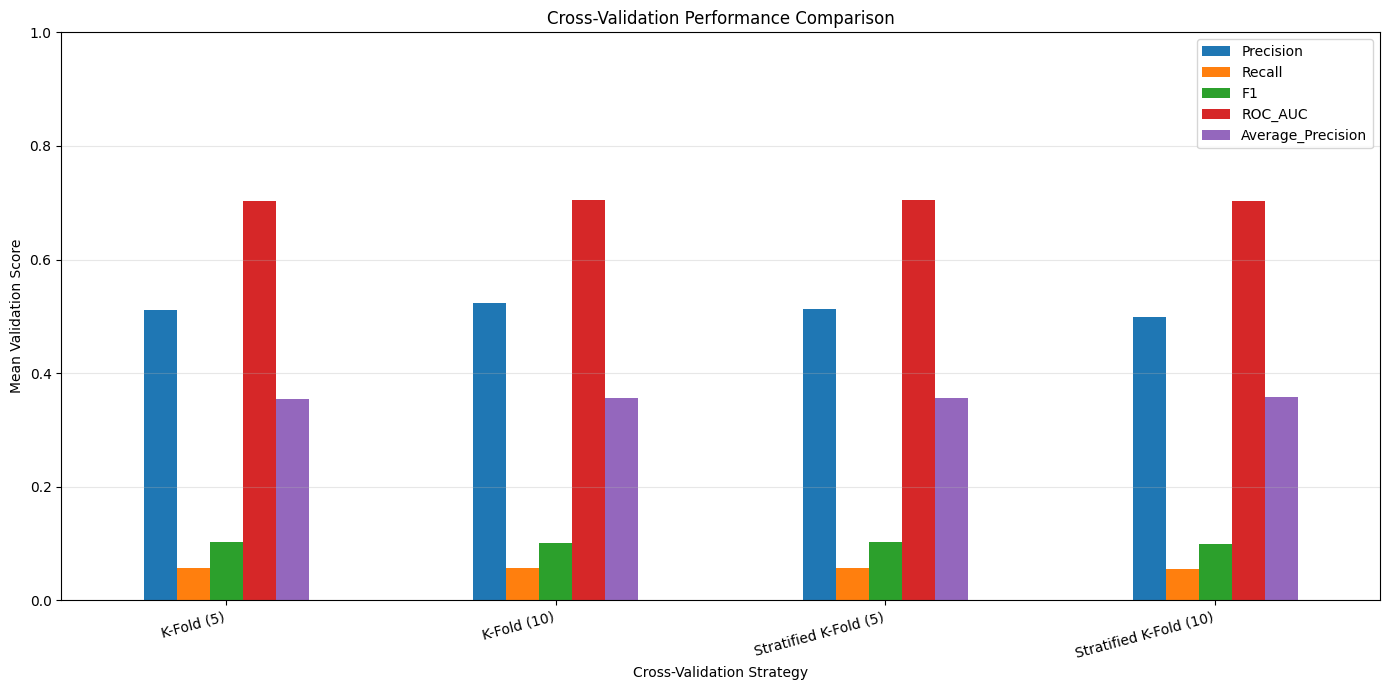

In [26]:
# Compare average validation performance

cv_metrics = [
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'Average_Precision'
]

cv_results_df.set_index('Method')[
    cv_metrics
].plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Cross-Validation Performance Comparison')
plt.ylabel('Mean Validation Score')
plt.xlabel('Cross-Validation Strategy')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

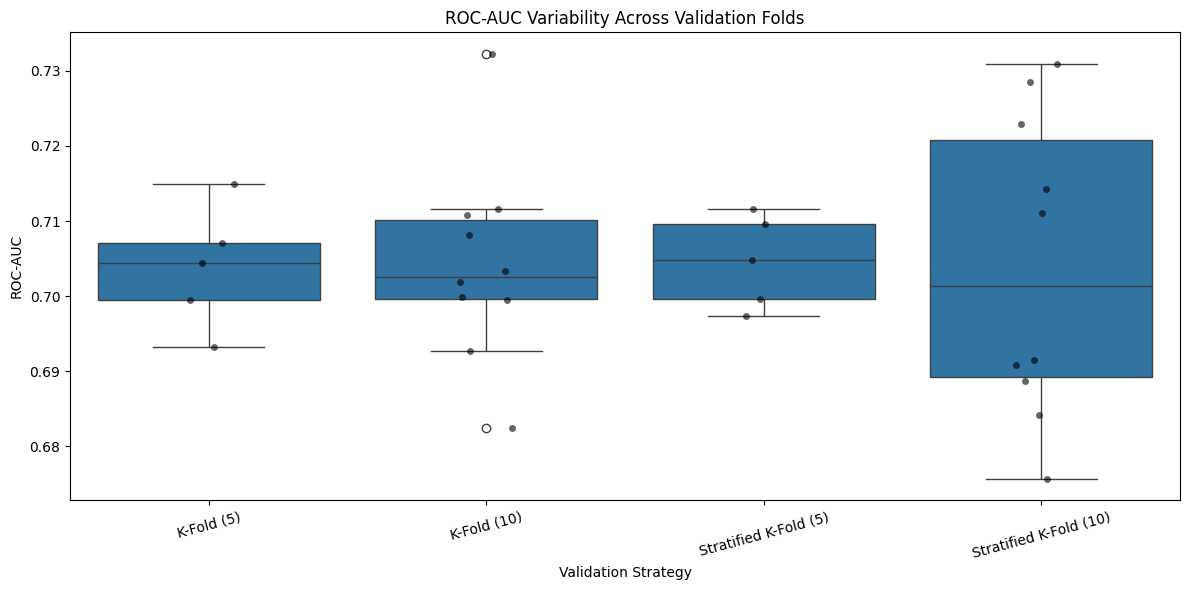

In [27]:
# Compare ROC-AUC variability

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=cv_fold_df[
        cv_fold_df['Metric'] == 'ROC_AUC'
    ],
    x='Method',
    y='Score'
)

sns.stripplot(
    data=cv_fold_df[
        cv_fold_df['Metric'] == 'ROC_AUC'
    ],
    x='Method',
    y='Score',
    color='black',
    alpha=0.6
)

plt.title('ROC-AUC Variability Across Validation Folds')
plt.xlabel('Validation Strategy')
plt.ylabel('ROC-AUC')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [28]:
fold_distribution = []

for name, strategy in cv_strategies.items():

    for fold, (train_idx, val_idx) in enumerate(
        strategy.split(X_exp, y_exp), 1
    ):

        fold_distribution.append({
            'Method': name,
            'Fold': fold,
            'Training Default Rate (%)':
                y_exp.iloc[train_idx].mean() * 100,

            'Validation Default Rate (%)':
                y_exp.iloc[val_idx].mean() * 100
        })

fold_distribution_df = pd.DataFrame(
    fold_distribution
)

display(fold_distribution_df.round(4))

distribution_summary = (
    fold_distribution_df.groupby('Method')[
        'Validation Default Rate (%)'
    ].agg(['mean', 'std', 'min', 'max'])
)

display(distribution_summary.round(4))

,Method,Fold,Training Default Rate (%),Validation Default Rate (%)
0,K-Fold (5),1,18.8625,19.500
1,K-Fold (5),2,19.0062,18.925
2,K-Fold (5),3,19.0438,18.775
3,K-Fold (5),4,19.0125,18.900
4,K-Fold (5),5,19.0250,18.850
5,K-Fold (10),1,19.0222,18.700
6,K-Fold (10),2,18.8444,20.300
7,K-Fold (10),3,19.0167,18.750
8,K-Fold (10),4,18.9778,19.100
9,K-Fold (10),5,18.9278,19.550


,mean,std,min,max
Method,,,,
K-Fold (10),18.99,0.6724,18.000,20.3
K-Fold (5),18.99,0.2908,18.775,19.5
Stratified K-Fold (10),18.99,0.0211,18.950,19.0
Stratified K-Fold (5),18.99,0.0137,18.975,19.0


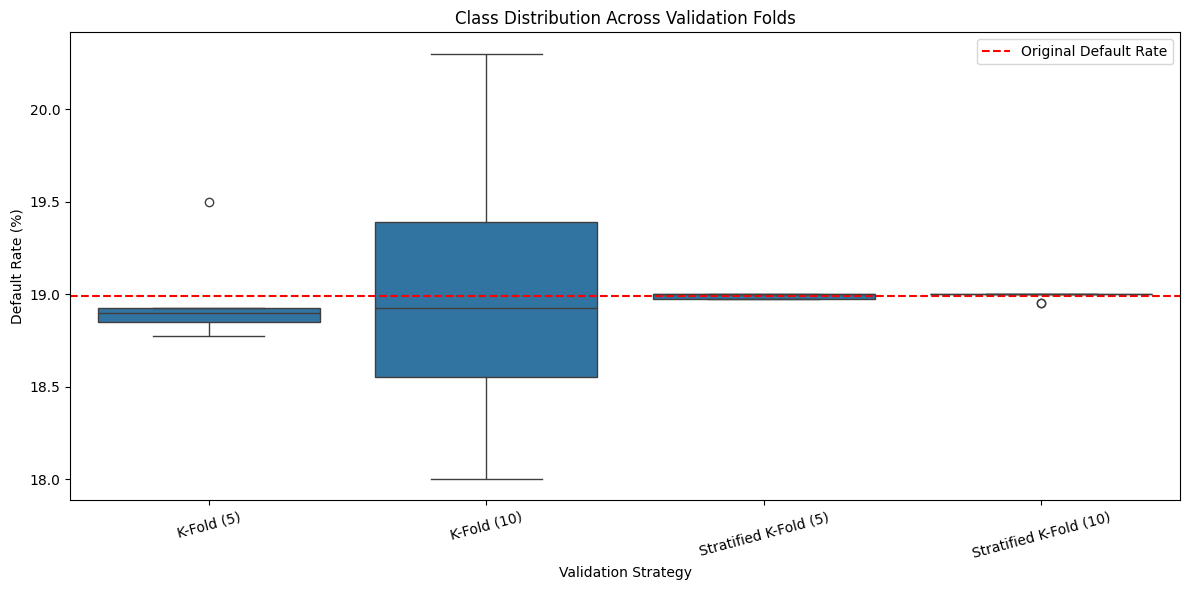

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=fold_distribution_df,
    x='Method',
    y='Validation Default Rate (%)'
)

plt.axhline(
    y=y_exp.mean() * 100,
    color='red',
    linestyle='--',
    label='Original Default Rate'
)

plt.title('Class Distribution Across Validation Folds')
plt.xlabel('Validation Strategy')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
# Create a smaller stratified subset for LOOCV

X_loo, _, y_loo, _ = train_test_split(
    X_exp,
    y_exp,
    train_size=300,
    stratify=y_exp,
    random_state=RANDOM_STATE
)

print("LOOCV sample size:", len(X_loo))

print("\nClass distribution:")
display(y_loo.value_counts())

loo = LeaveOneOut()

start_time = time.time()

# Obtain out-of-fold probabilities
loo_probabilities = cross_val_predict(
    clone(validation_model),
    X_loo,
    y_loo,
    cv=loo,
    method='predict_proba',
    n_jobs=2
)[:, 1]

loo_predictions = (
    loo_probabilities >= 0.5
).astype(int)

loo_result = {
    'Method': 'LOOCV',
    'Sample Size': len(X_loo),
    'Folds': len(X_loo),
    'Accuracy': accuracy_score(
        y_loo, loo_predictions
    ),
    'Precision': precision_score(
        y_loo, loo_predictions,
        zero_division=0
    ),
    'Recall': recall_score(
        y_loo, loo_predictions,
        zero_division=0
    ),
    'F1': f1_score(
        y_loo, loo_predictions,
        zero_division=0
    ),
    'ROC_AUC': roc_auc_score(
        y_loo, loo_probabilities
    ),
    'Average_Precision': average_precision_score(
        y_loo, loo_probabilities
    ),
    'Execution Time (s)': time.time() - start_time
}

loo_results_df = pd.DataFrame([loo_result])

display(loo_results_df.round(4))

LOOCV sample size: 300

Class distribution:


,count
default,
0,243
1,57


,Method,Sample Size,Folds,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Execution Time (s)
0,LOOCV,300,300,0.7933,0.0,0.0,0.0,0.4688,0.1712,11.7794


In [31]:
small_sample_results = [loo_result]

small_sample_strategies = {
    'K-Fold (5) - Small Sample': KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    ),

    'Stratified K-Fold (5) - Small Sample':
        StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        )
}

for name, strategy in small_sample_strategies.items():

    start_time = time.time()

    probabilities = cross_val_predict(
        clone(validation_model),
        X_loo,
        y_loo,
        cv=strategy,
        method='predict_proba',
        n_jobs=2
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    small_sample_results.append({
        'Method': name,
        'Sample Size': len(X_loo),
        'Folds': strategy.get_n_splits(),
        'Accuracy': accuracy_score(
            y_loo, predictions
        ),
        'Precision': precision_score(
            y_loo, predictions,
            zero_division=0
        ),
        'Recall': recall_score(
            y_loo, predictions,
            zero_division=0
        ),
        'F1': f1_score(
            y_loo, predictions,
            zero_division=0
        ),
        'ROC_AUC': roc_auc_score(
            y_loo, probabilities
        ),
        'Average_Precision': average_precision_score(
            y_loo, probabilities
        ),
        'Execution Time (s)': time.time() - start_time
    })

small_sample_results_df = pd.DataFrame(
    small_sample_results
)

display(small_sample_results_df.round(4))

,Method,Sample Size,Folds,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Execution Time (s)
0,LOOCV,300,300,0.7933,0.0,0.0,0.0,0.4688,0.1712,11.7794
1,K-Fold (5) - Small Sample,300,5,0.8100,0.0,0.0,0.0,0.6070,0.2626,0.4232
2,Stratified K-Fold (5) - Small Sample,300,5,0.7933,0.0,0.0,0.0,0.6135,0.2365,0.3362


In [32]:
# Align issuance dates with experimental records

exp_dates = train_dates.loc[X_exp.index]

sorted_indices = exp_dates.sort_values().index

X_time = X_exp.loc[sorted_indices].reset_index(
    drop=True
)

y_time = y_exp.loc[sorted_indices].reset_index(
    drop=True
)

dates_time = exp_dates.loc[
    sorted_indices
].reset_index(drop=True)

# Create chronological monthly groups

months = dates_time.dt.to_period('M')

unique_months = pd.Index(
    months.unique()
).sort_values()

tscv = TimeSeriesSplit(n_splits=5)

time_series_results = []

for fold, (train_months, val_months) in enumerate(
    tscv.split(unique_months), 1
):

    training_periods = unique_months[train_months]
    validation_periods = unique_months[val_months]

    train_idx = np.flatnonzero(
        months.isin(training_periods)
    )

    val_idx = np.flatnonzero(
        months.isin(validation_periods)
    )

    X_fold_train = X_time.iloc[train_idx]
    y_fold_train = y_time.iloc[train_idx]

    X_fold_val = X_time.iloc[val_idx]
    y_fold_val = y_time.iloc[val_idx]

    model = clone(validation_model)

    model.fit(X_fold_train, y_fold_train)

    probabilities = model.predict_proba(
        X_fold_val
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    time_series_results.append({
        'Fold': fold,
        'Training Records': len(train_idx),
        'Validation Records': len(val_idx),

        'Training End':
            str(training_periods[-1]),

        'Validation Start':
            str(validation_periods[0]),

        'Validation End':
            str(validation_periods[-1]),

        'Default Rate (%)':
            y_fold_val.mean() * 100,

        'Accuracy': accuracy_score(
            y_fold_val, predictions
        ),

        'Precision': precision_score(
            y_fold_val, predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_fold_val, predictions,
            zero_division=0
        ),

        'F1': f1_score(
            y_fold_val, predictions,
            zero_division=0
        ),

        'ROC_AUC': roc_auc_score(
            y_fold_val, probabilities
        ),

        'Average_Precision':
            average_precision_score(
                y_fold_val, probabilities
            )
    })

    print(f"Completed chronological fold {fold}")

time_series_results_df = pd.DataFrame(
    time_series_results
)

display(time_series_results_df.round(4))

Completed chronological fold 1
Completed chronological fold 2
Completed chronological fold 3
Completed chronological fold 4
Completed chronological fold 5


,Fold,Training Records,Validation Records,Training End,Validation Start,Validation End,Default Rate (%),Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
0,1,209,621,2009-02,2009-03,2010-04,13.5266,0.8631,0.0000,0.0000,0.0000,0.5135,0.1365
1,2,830,1427,2010-04,2010-05,2011-06,14.8563,0.8507,0.3333,0.0047,0.0093,0.6938,0.2663
2,3,2257,3283,2011-06,2011-07,2012-08,16.5398,0.8352,0.5125,0.0755,0.1316,0.6911,0.3338
3,4,5540,7023,2012-08,2012-09,2013-10,19.2510,0.8056,0.4637,0.0614,0.1084,0.6267,0.2964
4,5,12563,7437,2013-10,2013-11,2014-12,21.2048,0.7862,0.4726,0.0710,0.1235,0.6949,0.3649


In [33]:
# Summarize chronological validation performance

time_summary = {
    'Method': 'Time-Series Split (5)',
    'Folds': 5,
    'Sample Size': len(X_time)
}

for metric in scoring:

    time_summary[metric] = (
        time_series_results_df[metric].mean()
    )

    time_summary[f'{metric}_SD'] = (
        time_series_results_df[metric].std(ddof=1)
    )

# Combine full experimental sample results

all_cv_results_df = pd.concat([
    cv_results_df,
    pd.DataFrame([time_summary])
], ignore_index=True)

report_columns = [
    'Method',
    'Folds',
    'Sample Size',
    'Accuracy',
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'ROC_AUC_SD',
    'Average_Precision',
    'Average_Precision_SD'
]

display(
    all_cv_results_df[report_columns].round(4)
)

print("\nSeparate LOOCV comparison:")

display(small_sample_results_df.round(4))

,Method,Folds,Sample Size,Accuracy,Precision,Recall,F1,ROC_AUC,ROC_AUC_SD,Average_Precision,Average_Precision_SD
0,K-Fold (5),5,20000,0.8108,0.5102,0.0567,0.1018,0.7038,0.0082,0.3546,0.0074
1,K-Fold (10),10,20000,0.8109,0.5226,0.0562,0.1010,0.7043,0.0132,0.3564,0.0212
2,Stratified K-Fold (5),5,20000,0.8107,0.5134,0.0574,0.1030,0.7046,0.0061,0.3555,0.0085
3,Stratified K-Fold (10),10,20000,0.8102,0.4985,0.0550,0.0988,0.7039,0.0200,0.3573,0.0280
4,Time-Series Split (5),5,20000,0.8282,0.3564,0.0425,0.0746,0.6440,0.0785,0.2796,0.0882



Separate LOOCV comparison:


,Method,Sample Size,Folds,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Execution Time (s)
0,LOOCV,300,300,0.7933,0.0,0.0,0.0,0.4688,0.1712,11.7794
1,K-Fold (5) - Small Sample,300,5,0.8100,0.0,0.0,0.0,0.6070,0.2626,0.4232
2,Stratified K-Fold (5) - Small Sample,300,5,0.7933,0.0,0.0,0.0,0.6135,0.2365,0.3362


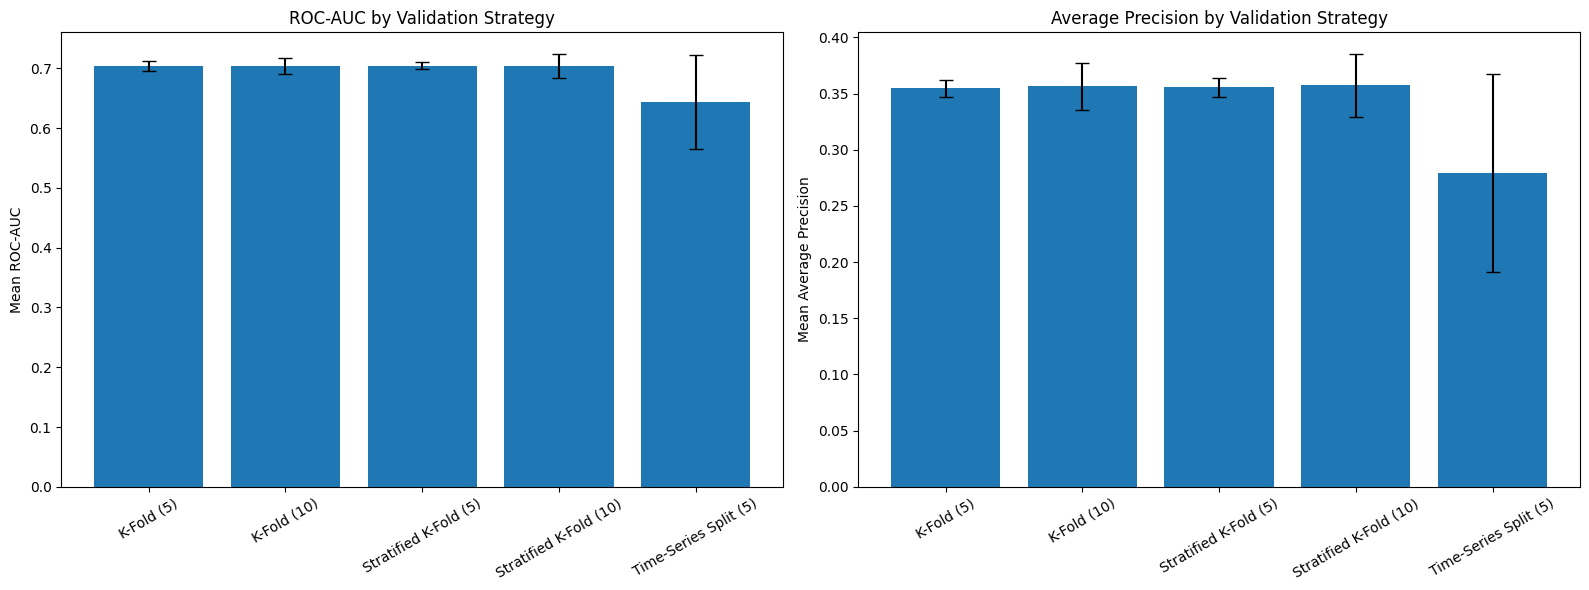

In [34]:
# Compare overall cross-validation performance

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

methods = all_cv_results_df['Method']

axes[0].bar(
    methods,
    all_cv_results_df['ROC_AUC'],
    yerr=all_cv_results_df['ROC_AUC_SD'],
    capsize=5
)

axes[0].set_title('ROC-AUC by Validation Strategy')
axes[0].set_ylabel('Mean ROC-AUC')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(
    methods,
    all_cv_results_df['Average_Precision'],
    yerr=all_cv_results_df['Average_Precision_SD'],
    capsize=5
)

axes[1].set_title(
    'Average Precision by Validation Strategy'
)

axes[1].set_ylabel('Mean Average Precision')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## Step 5: Resampling Methods for Imbalanced Data

The baseline model demonstrated low recall despite achieving
approximately 81% classification accuracy.

To address this limitation, seven resampling techniques and
a class-weighted model are evaluated against a baseline
without resampling.

All resampling operations are performed exclusively within
the training folds using an imbalanced-learn pipeline.

Stratified five-fold cross-validation is used to ensure
consistent class distributions and comparable evaluation.

Performance is assessed using accuracy, precision, recall,
F1-score, ROC-AUC, average precision, and score variability.

In [35]:
import imblearn

from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.over_sampling import (
    RandomOverSampler,
    SMOTE,
    ADASYN
)

from imblearn.under_sampling import (
    RandomUnderSampler,
    TomekLinks
)

from imblearn.combine import (
    SMOTEENN,
    SMOTETomek
)

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer
)

print("imbalanced-learn version:", imblearn.__version__)
print("Resampling libraries imported successfully.")

imbalanced-learn version: 0.14.2
Resampling libraries imported successfully.


In [36]:
%pip install imbalanced-learn

In [37]:
resampling_methods = {

    'Baseline': 'passthrough',

    'Random Oversampling': RandomOverSampler(
        random_state=RANDOM_STATE
    ),

    'Random Undersampling': RandomUnderSampler(
        random_state=RANDOM_STATE
    ),

    'SMOTE': SMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=5
    ),

    'ADASYN': ADASYN(
        random_state=RANDOM_STATE,
        n_neighbors=5
    ),

    'Tomek Links': TomekLinks(
        sampling_strategy='auto',
        n_jobs=2
    ),

    'SMOTE-ENN': SMOTEENN(
        random_state=RANDOM_STATE
    ),

    'SMOTE-Tomek': SMOTETomek(
        random_state=RANDOM_STATE
    ),

    'Class Weighting': 'passthrough'
}

print("Resampling strategies initialized:")

for name in resampling_methods:
    print(name)

Resampling strategies initialized:
Baseline
Random Oversampling
Random Undersampling
SMOTE
ADASYN
Tomek Links
SMOTE-ENN
SMOTE-Tomek
Class Weighting


In [38]:
# Use only the first cross-validation training fold

resampling_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

first_train_idx, first_val_idx = next(
    resampling_cv.split(X_exp, y_exp)
)

X_res_train = X_exp.iloc[first_train_idx]
y_res_train = y_exp.iloc[first_train_idx]

# Fit preprocessing on training data only

resample_preprocessor = clone(preprocessor)

X_res_processed = resample_preprocessor.fit_transform(
    X_res_train
)

# Apply LASSO feature selection

resample_selector = clone(
    feature_selectors['LASSO (L1)']
)

X_res_selected = resample_selector.fit_transform(
    X_res_processed,
    y_res_train
)

resampling_distribution = []

for name, sampler in resampling_methods.items():

    print(f"Examining: {name}")

    if isinstance(sampler, str):

        X_resampled = X_res_selected
        y_resampled = y_res_train

    else:

        X_resampled, y_resampled = (
            clone(sampler).fit_resample(
                X_res_selected,
                y_res_train
            )
        )

    counts = pd.Series(y_resampled).value_counts()

    resampling_distribution.append({
        'Method': name,
        'Non-Default': counts.get(0, 0),
        'Default': counts.get(1, 0),
        'Total Records': len(y_resampled),
        'Default Rate (%)': (
            np.mean(y_resampled) * 100
        )
    })

resampling_distribution_df = pd.DataFrame(
    resampling_distribution
)

display(resampling_distribution_df.round(2))

Examining: Baseline
Examining: Random Oversampling
Examining: Random Undersampling
Examining: SMOTE
Examining: ADASYN
Examining: Tomek Links
Examining: SMOTE-ENN
Examining: SMOTE-Tomek
Examining: Class Weighting


,Method,Non-Default,Default,Total Records,Default Rate (%)
0,Baseline,12961,3039,16000,18.99
1,Random Oversampling,12961,12961,25922,50.00
2,Random Undersampling,3039,3039,6078,50.00
3,SMOTE,12961,12961,25922,50.00
4,ADASYN,12961,12521,25482,49.14
5,Tomek Links,12183,3039,15222,19.96
6,SMOTE-ENN,5143,12278,17421,70.48
7,SMOTE-Tomek,12943,12943,25886,50.00
8,Class Weighting,12961,3039,16000,18.99


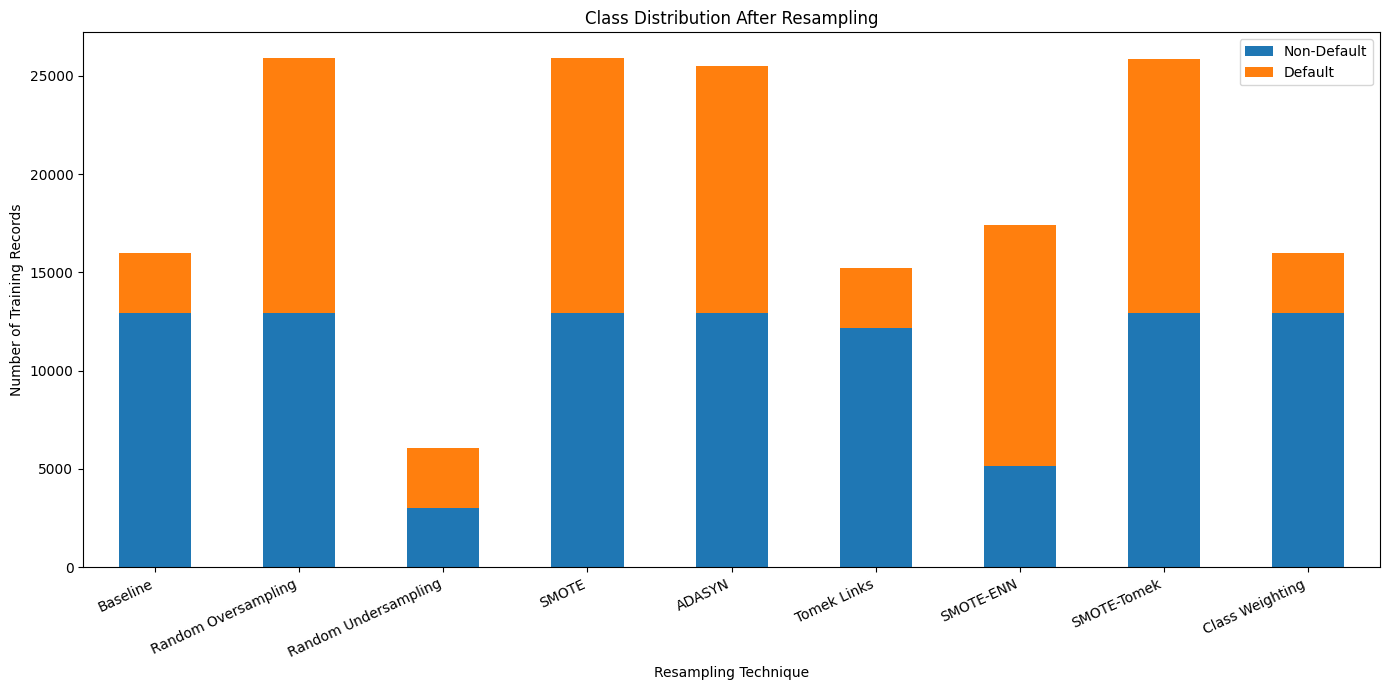

In [39]:
resampling_distribution_df.set_index('Method')[
    ['Non-Default', 'Default']
].plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title('Class Distribution After Resampling')
plt.xlabel('Resampling Technique')
plt.ylabel('Number of Training Records')
plt.xticks(rotation=25, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
resampling_pipelines = {}

for name, sampler in resampling_methods.items():

    classifier = clone(base_model)

    if name == 'Class Weighting':
        classifier.set_params(
            class_weight='balanced'
        )

    pipeline = ImbPipeline([

        ('preprocessor', clone(preprocessor)),

        ('selector', clone(
            feature_selectors['LASSO (L1)']
        )),

        ('sampler', sampler),

        ('classifier', classifier)

    ])

    resampling_pipelines[name] = pipeline

print("Created", len(resampling_pipelines),
      "resampling pipelines.")

Created 9 resampling pipelines.


In [41]:
resampling_scoring = {
    'Accuracy': 'accuracy',

    'Precision': make_scorer(
        precision_score,
        zero_division=0
    ),

    'Recall': make_scorer(
        recall_score,
        zero_division=0
    ),

    'F1': make_scorer(
        f1_score,
        zero_division=0
    ),

    'ROC_AUC': 'roc_auc',

    'Average_Precision': 'average_precision',

    'Balanced_Accuracy': 'balanced_accuracy'
}

resampling_results = []
resampling_fold_results = []

for name, pipeline in resampling_pipelines.items():

    print(f"Evaluating: {name}")

    start_time = time.time()

    scores = cross_validate(
        clone(pipeline),
        X_exp,
        y_exp,
        cv=resampling_cv,
        scoring=resampling_scoring,
        n_jobs=2,
        error_score='raise'
    )

    result = {'Method': name}

    for metric in resampling_scoring:

        values = scores[f'test_{metric}']

        result[metric] = values.mean()

        result[f'{metric}_SD'] = values.std(
            ddof=1
        )

        for fold, value in enumerate(values, 1):

            resampling_fold_results.append({
                'Method': name,
                'Fold': fold,
                'Metric': metric,
                'Score': value
            })

    result['Execution Time (s)'] = (
        time.time() - start_time
    )

    resampling_results.append(result)

resampling_results_df = pd.DataFrame(
    resampling_results
)

resampling_fold_df = pd.DataFrame(
    resampling_fold_results
)

resampling_results_df = (
    resampling_results_df.sort_values(
        'F1',
        ascending=False
    )
)

display(resampling_results_df.round(4))

Evaluating: Baseline
Evaluating: Random Oversampling
Evaluating: Random Undersampling
Evaluating: SMOTE
Evaluating: ADASYN
Evaluating: Tomek Links
Evaluating: SMOTE-ENN
Evaluating: SMOTE-Tomek
Evaluating: Class Weighting


,Method,Accuracy,Accuracy_SD,Precision,Precision_SD,Recall,Recall_SD,F1,F1_SD,ROC_AUC,ROC_AUC_SD,Average_Precision,Average_Precision_SD,Balanced_Accuracy,Balanced_Accuracy_SD,Execution Time (s)
1,Random Oversampling,0.6411,0.0077,0.2981,0.0056,0.6564,0.0062,0.4100,0.0057,0.7042,0.0063,0.3549,0.0083,0.6470,0.0053,2.4723
8,Class Weighting,0.6395,0.0084,0.2968,0.0054,0.6556,0.0076,0.4085,0.0050,0.7044,0.0063,0.3552,0.0085,0.6456,0.0046,2.1804
2,Random Undersampling,0.6381,0.0067,0.2957,0.0038,0.6553,0.0076,0.4075,0.0031,0.7026,0.0070,0.3511,0.0099,0.6447,0.0029,2.1218
4,ADASYN,0.6325,0.0097,0.2921,0.0073,0.6564,0.0109,0.4042,0.0082,0.6992,0.0075,0.3488,0.0092,0.6417,0.0080,4.7137
3,SMOTE,0.6339,0.0089,0.2922,0.0070,0.6519,0.0094,0.4035,0.0079,0.6996,0.0072,0.3505,0.0093,0.6408,0.0077,2.9017
7,SMOTE-Tomek,0.6334,0.0088,0.2917,0.0069,0.6511,0.0097,0.4029,0.0078,0.6996,0.0071,0.3506,0.0094,0.6402,0.0076,19.9072
6,SMOTE-ENN,0.4496,0.0153,0.2404,0.0056,0.8786,0.0155,0.3775,0.0074,0.7001,0.0071,0.3488,0.0130,0.6139,0.0105,19.5722
5,Tomek Links,0.8100,0.0029,0.4986,0.0400,0.0924,0.0095,0.1559,0.0151,0.7044,0.0061,0.3554,0.0094,0.5353,0.0051,8.1300
0,Baseline,0.8107,0.0020,0.5134,0.0512,0.0574,0.0132,0.1030,0.0219,0.7046,0.0061,0.3555,0.0085,0.5223,0.0059,5.1686


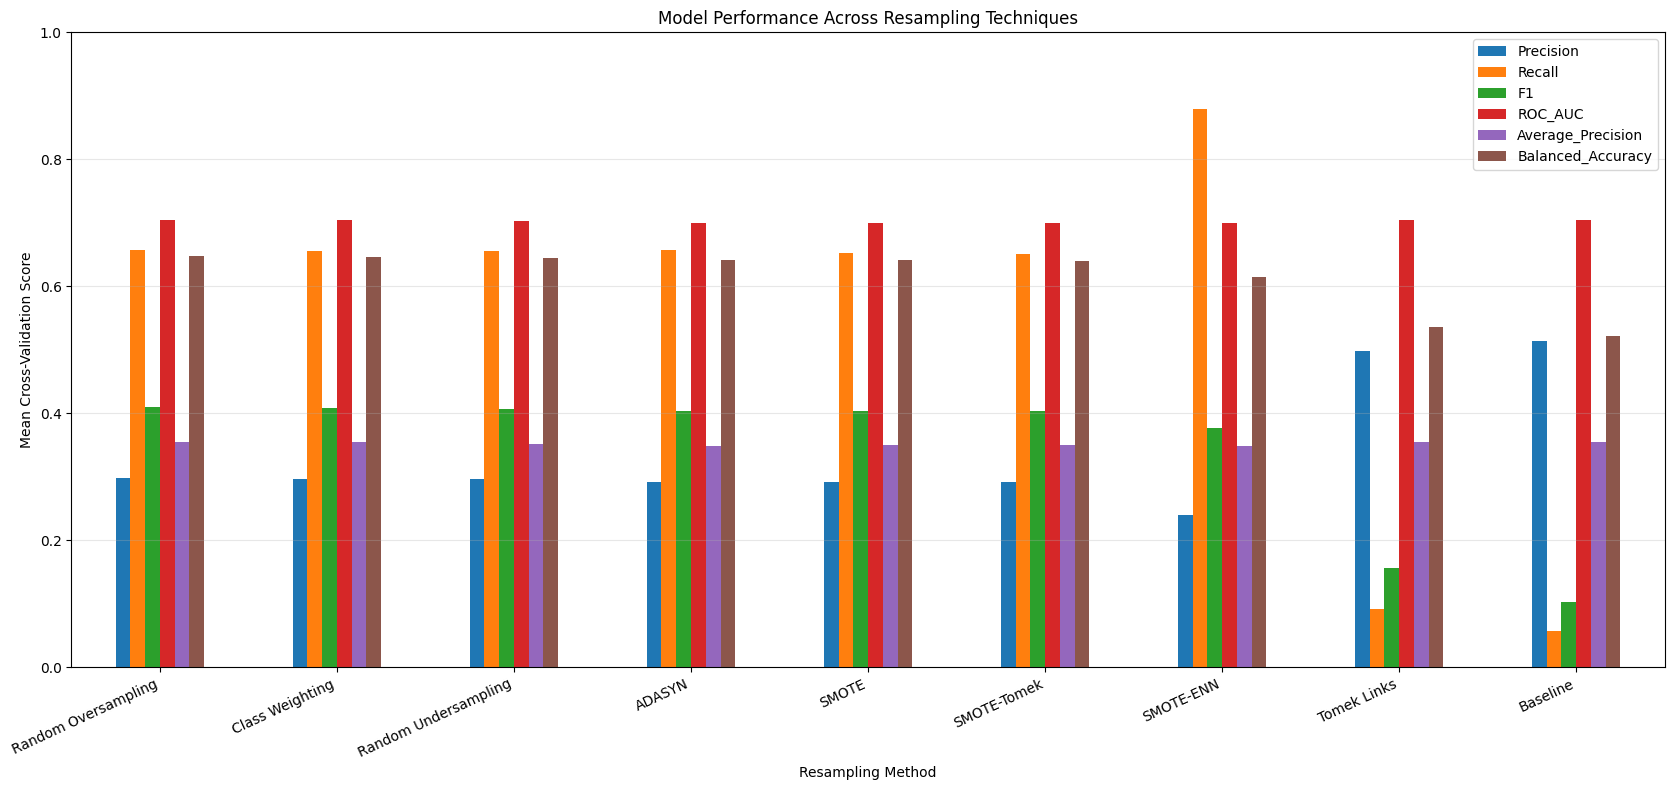

In [42]:
comparison_metrics = [
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'Average_Precision',
    'Balanced_Accuracy'
]

resampling_results_df.set_index('Method')[
    comparison_metrics
].plot(
    kind='bar',
    figsize=(17, 8)
)

plt.title('Model Performance Across Resampling Techniques')
plt.ylabel('Mean Cross-Validation Score')
plt.xlabel('Resampling Method')
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [43]:
baseline = resampling_results_df.loc[
    resampling_results_df['Method'] == 'Baseline'
].iloc[0]

improvement_df = resampling_results_df[
    ['Method', 'Precision', 'Recall',
     'F1', 'ROC_AUC', 'Average_Precision']
].copy()

for metric in [
    'Recall',
    'F1',
    'ROC_AUC',
    'Average_Precision'
]:

    improvement_df[f'{metric}_Change'] = (
        improvement_df[metric] -
        baseline[metric]
    )

display(improvement_df.round(4))

print("Highest recall method:")

display(
    resampling_results_df.nlargest(
        1, 'Recall'
    )[['Method', 'Recall', 'Precision', 'F1']]
)

print("\nHighest F1 method:")

display(
    resampling_results_df.nlargest(
        1, 'F1'
    )[['Method', 'F1', 'Recall', 'Precision']]
)

print("\nHighest average precision method:")

display(
    resampling_results_df.nlargest(
        1, 'Average_Precision'
    )[['Method', 'Average_Precision', 'ROC_AUC']]
)

,Method,Precision,Recall,F1,ROC_AUC,Average_Precision,Recall_Change,F1_Change,ROC_AUC_Change,Average_Precision_Change
1,Random Oversampling,0.2981,0.6564,0.4100,0.7042,0.3549,0.5990,0.3070,-0.0004,-0.0006
8,Class Weighting,0.2968,0.6556,0.4085,0.7044,0.3552,0.5982,0.3056,-0.0001,-0.0003
2,Random Undersampling,0.2957,0.6553,0.4075,0.7026,0.3511,0.5979,0.3046,-0.0020,-0.0044
4,ADASYN,0.2921,0.6564,0.4042,0.6992,0.3488,0.5990,0.3013,-0.0054,-0.0067
3,SMOTE,0.2922,0.6519,0.4035,0.6996,0.3505,0.5945,0.3006,-0.0050,-0.0051
7,SMOTE-Tomek,0.2917,0.6511,0.4029,0.6996,0.3506,0.5937,0.2999,-0.0049,-0.0050
6,SMOTE-ENN,0.2404,0.8786,0.3775,0.7001,0.3488,0.8212,0.2746,-0.0045,-0.0067
5,Tomek Links,0.4986,0.0924,0.1559,0.7044,0.3554,0.0350,0.0529,-0.0002,-0.0001
0,Baseline,0.5134,0.0574,0.1030,0.7046,0.3555,0.0000,0.0000,0.0000,0.0000


Highest recall method:


,Method,Recall,Precision,F1
6,SMOTE-ENN,0.878625,0.240447,0.377536



Highest F1 method:


,Method,F1,Recall,Precision
1,Random Oversampling,0.409979,0.656401,0.298105



Highest average precision method:


,Method,Average_Precision,ROC_AUC
0,Baseline,0.355507,0.704585


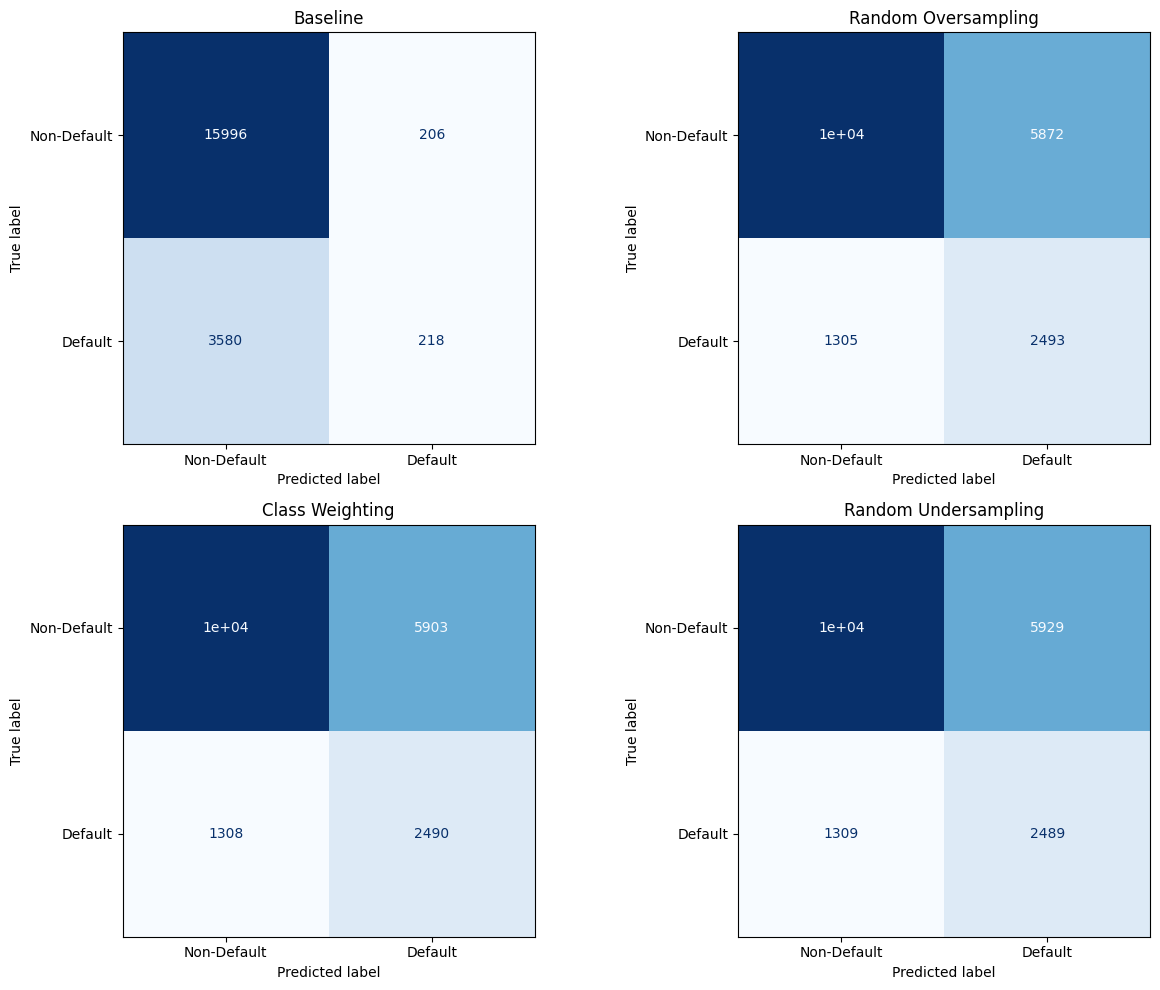

,Method,True Negatives,False Positives,False Negatives,True Positives
0,Baseline,15996,206,3580,218
1,Random Oversampling,10330,5872,1305,2493
2,Class Weighting,10299,5903,1308,2490
3,Random Undersampling,10273,5929,1309,2489


In [44]:
top_resampling_methods = (
    resampling_results_df[
        resampling_results_df['Method'] != 'Baseline'
    ]
    .nlargest(3, 'F1')['Method']
    .tolist()
)

comparison_methods = [
    'Baseline'
] + top_resampling_methods

resampling_oof = {}
confusion_results = []

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for ax, name in zip(
    axes.ravel(),
    comparison_methods
):

    probabilities = cross_val_predict(
        clone(resampling_pipelines[name]),
        X_exp,
        y_exp,
        cv=resampling_cv,
        method='predict_proba',
        n_jobs=2
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    resampling_oof[name] = probabilities

    cm = confusion_matrix(
        y_exp,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    confusion_results.append({
        'Method': name,
        'True Negatives': tn,
        'False Positives': fp,
        'False Negatives': fn,
        'True Positives': tp
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Non-Default', 'Default']
    ).plot(
        ax=ax,
        cmap='Blues',
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

confusion_results_df = pd.DataFrame(
    confusion_results
)

display(confusion_results_df)

In [45]:
# Hypothetical relative error costs

FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1

cost_analysis_df = confusion_results_df.copy()

cost_analysis_df['False Negative Cost'] = (
    cost_analysis_df['False Negatives'] *
    FALSE_NEGATIVE_COST
)

cost_analysis_df['False Positive Cost'] = (
    cost_analysis_df['False Positives'] *
    FALSE_POSITIVE_COST
)

cost_analysis_df['Total Relative Cost'] = (
    cost_analysis_df['False Negative Cost'] +
    cost_analysis_df['False Positive Cost']
)

baseline_cost = cost_analysis_df.loc[
    cost_analysis_df['Method'] == 'Baseline',
    'Total Relative Cost'
].iloc[0]

cost_analysis_df['Cost Reduction (%)'] = (
    (baseline_cost -
     cost_analysis_df['Total Relative Cost'])
    / baseline_cost * 100
)

display(
    cost_analysis_df.sort_values(
        'Total Relative Cost'
    ).round(2)
)

,Method,True Negatives,False Positives,False Negatives,True Positives,False Negative Cost,False Positive Cost,Total Relative Cost,Cost Reduction (%)
1,Random Oversampling,10330,5872,1305,2493,6525,5872,12397,31.53
2,Class Weighting,10299,5903,1308,2490,6540,5903,12443,31.28
3,Random Undersampling,10273,5929,1309,2489,6545,5929,12474,31.11
0,Baseline,15996,206,3580,218,17900,206,18106,0.00


## Step 6: Bootstrap Analysis

Bootstrap resampling is used to assess the stability,
uncertainty, and reliability of the credit risk model.

Random Oversampling with LASSO feature selection and
Logistic Regression is selected as the provisional model
based on its cross-validation F1-score and balanced
accuracy.

The analysis includes:

- 100 bootstrap training iterations.
- Out-of-bag performance and error estimation.
- Model stability across bootstrap iterations.
- 95% percentile confidence intervals.
- 95% bias-corrected and accelerated (BCa) intervals.

Bootstrap training variability and confidence intervals
for fixed-model evaluation are analyzed separately.

The independent 2015 holdout dataset remains untouched.

In [46]:
from sklearn.utils import resample

from sklearn.metrics import (
    balanced_accuracy_score,
    brier_score_loss
)

from scipy.stats import bootstrap

from tqdm.auto import tqdm

import warnings

# Bootstrap configuration

N_BOOTSTRAPS = 100
N_CI_RESAMPLES = 2000
CONFIDENCE_LEVEL = 0.95

# Select candidate and baseline models

bootstrap_model = clone(
    resampling_pipelines['Random Oversampling']
)

bootstrap_baseline = clone(
    resampling_pipelines['Baseline']
)

rng = np.random.default_rng(RANDOM_STATE)

print("Bootstrap training iterations:", N_BOOTSTRAPS)
print("Confidence interval resamples:", N_CI_RESAMPLES)
print("Confidence level:", CONFIDENCE_LEVEL)

Bootstrap training iterations: 100
Confidence interval resamples: 2000
Confidence level: 0.95


In [47]:
def evaluate_bootstrap_metrics(
    y_true,
    probabilities,
    threshold=0.5
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        'Accuracy': accuracy_score(
            y_true, predictions
        ),

        'Precision': precision_score(
            y_true, predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_true, predictions,
            zero_division=0
        ),

        'F1': f1_score(
            y_true, predictions,
            zero_division=0
        ),

        'ROC_AUC': roc_auc_score(
            y_true, probabilities
        ),

        'Average_Precision':
            average_precision_score(
                y_true, probabilities
            ),

        'Balanced_Accuracy':
            balanced_accuracy_score(
                y_true, predictions
            ),

        'OOB_Error': 1 - accuracy_score(
            y_true, predictions
        )
    }

print("Bootstrap evaluation function created.")

Bootstrap evaluation function created.


In [48]:
bootstrap_results = []

n_samples = len(X_exp)

all_indices = np.arange(n_samples)

rng = np.random.default_rng(RANDOM_STATE)

bootstrap_models = {
    'Baseline': bootstrap_baseline,
    'Random Oversampling': bootstrap_model
}

start_time = time.time()

for iteration in tqdm(
    range(N_BOOTSTRAPS),
    desc="Bootstrap iterations"
):

    # Sample observations with replacement

    bootstrap_indices = rng.choice(
        all_indices,
        size=n_samples,
        replace=True
    )

    # Identify out-of-bag observations

    unique_train_indices = np.unique(
        bootstrap_indices
    )

    oob_indices = np.setdiff1d(
        all_indices,
        unique_train_indices
    )

    X_boot = X_exp.iloc[bootstrap_indices]
    y_boot = y_exp.iloc[bootstrap_indices]

    X_oob = X_exp.iloc[oob_indices]
    y_oob = y_exp.iloc[oob_indices]

    # Skip invalid samples if necessary

    if (
        y_boot.nunique() < 2 or
        y_oob.nunique() < 2
    ):
        continue

    for model_name, pipeline in bootstrap_models.items():

        model = clone(pipeline)

        model.fit(X_boot, y_boot)

        probabilities = model.predict_proba(
            X_oob
        )[:, 1]

        result = evaluate_bootstrap_metrics(
            y_oob,
            probabilities
        )

        result.update({
            'Iteration': iteration + 1,
            'Model': model_name,
            'Bootstrap Size': len(bootstrap_indices),
            'Unique Training Records':
                len(unique_train_indices),
            'OOB Size': len(oob_indices),
            'OOB Default Rate': y_oob.mean()
        })

        bootstrap_results.append(result)

bootstrap_results_df = pd.DataFrame(
    bootstrap_results
)

print("\nBootstrap analysis completed.")

print("Total model evaluations:",
      len(bootstrap_results_df))

print("Execution time:",
      round(time.time() - start_time, 2),
      "seconds")

display(bootstrap_results_df.head(10))

Bootstrap iterations:   0%|          | 0/100 [00:00<?, ?it/s]


Bootstrap analysis completed.
Total model evaluations: 200
Execution time: 264.78 seconds


,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,OOB_Error,Iteration,Model,Bootstrap Size,Unique Training Records,OOB Size,OOB Default Rate
0,0.811225,0.474227,0.067202,0.117722,0.693062,0.336852,0.525010,0.188775,1,Baseline,20000,12695,7305,0.187406
1,0.639151,0.289605,0.636961,0.398174,0.694590,0.338274,0.638309,0.360849,1,Random Oversampling,20000,12695,7305,0.187406
2,0.815743,0.502959,0.062135,0.110605,0.700633,0.341016,0.524126,0.184257,2,Baseline,20000,12581,7419,0.184391
3,0.648066,0.293590,0.646199,0.403745,0.700491,0.341874,0.647343,0.351934,2,Random Oversampling,20000,12581,7419,0.184391
4,0.816646,0.494382,0.064945,0.114808,0.707503,0.346594,0.525029,0.183354,3,Baseline,20000,12599,7401,0.183083
5,0.639778,0.288617,0.660517,0.401706,0.707167,0.348189,0.647824,0.360222,3,Random Oversampling,20000,12599,7401,0.183083
6,0.810999,0.468750,0.065550,0.115016,0.693881,0.340604,0.524211,0.189001,4,Baseline,20000,12672,7328,0.187364
7,0.642740,0.291457,0.633649,0.399266,0.693493,0.340737,0.639243,0.357260,4,Random Oversampling,20000,12672,7328,0.187364
8,0.808101,0.545455,0.042343,0.078585,0.703674,0.359147,0.516945,0.191899,5,Baseline,20000,12668,7332,0.193262
9,0.645663,0.304146,0.647142,0.413809,0.702753,0.355010,0.646225,0.354337,5,Random Oversampling,20000,12668,7332,0.193262


In [49]:
bootstrap_metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'Average_Precision',
    'Balanced_Accuracy',
    'OOB_Error'
]

bootstrap_summary = []

for model_name, group in bootstrap_results_df.groupby(
    'Model'
):

    for metric in bootstrap_metrics:

        values = group[metric]

        bootstrap_summary.append({
            'Model': model_name,
            'Metric': metric,
            'Mean': values.mean(),
            'Standard Deviation': values.std(ddof=1),
            'Minimum': values.min(),
            'Maximum': values.max(),
            '2.5th Percentile': values.quantile(0.025),
            '97.5th Percentile': values.quantile(0.975)
        })

bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary
)

display(bootstrap_summary_df.round(4))

print("\nAverage OOB sample sizes:")

display(
    bootstrap_results_df.groupby('Model')[
        [
            'Unique Training Records',
            'OOB Size',
            'OOB Default Rate'
        ]
    ].mean().round(4)
)

,Model,Metric,Mean,Standard Deviation,Minimum,Maximum,2.5th Percentile,97.5th Percentile
0,Baseline,Accuracy,0.8103,0.0039,0.8008,0.8174,0.8025,0.8171
1,Baseline,Precision,0.4948,0.0357,0.4270,0.5960,0.4319,0.5692
2,Baseline,Recall,0.0625,0.0084,0.0395,0.0817,0.0432,0.0757
3,Baseline,F1,0.1108,0.0133,0.0730,0.1409,0.0791,0.1300
4,Baseline,ROC_AUC,0.6992,0.0062,0.6833,0.7131,0.6858,0.7097
5,Baseline,Average_Precision,0.3463,0.0093,0.3274,0.3778,0.3301,0.3654
6,Baseline,Balanced_Accuracy,0.5238,0.0034,0.5145,0.5317,0.5164,0.5293
7,Baseline,OOB_Error,0.1897,0.0039,0.1826,0.1992,0.1829,0.1975
8,Random Oversampling,Accuracy,0.6397,0.0064,0.6225,0.6549,0.6276,0.6515
9,Random Oversampling,Precision,0.2948,0.0071,0.2726,0.3115,0.2819,0.3088



Average OOB sample sizes:


,Unique Training Records,OOB Size,OOB Default Rate
Model,,,
Baseline,12643.34,7356.66,0.1893
Random Oversampling,12643.34,7356.66,0.1893


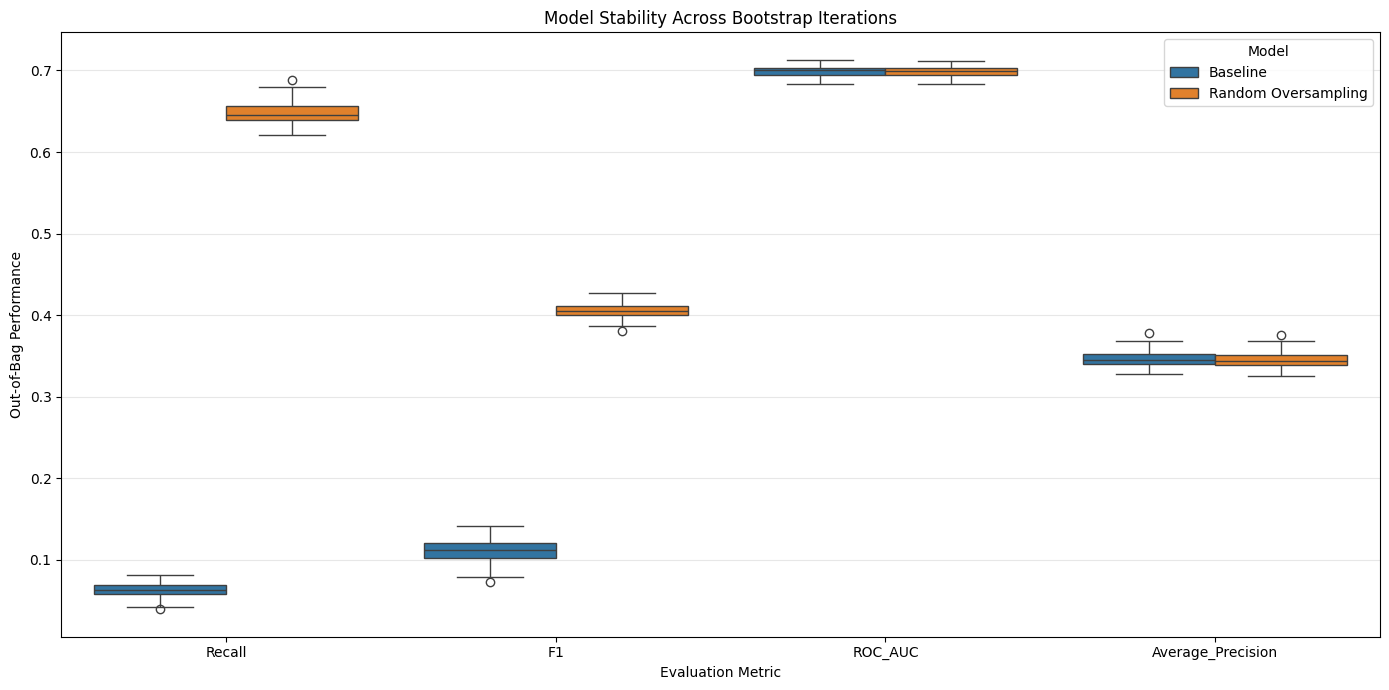

In [50]:
# Compare metric distributions across models

plot_metrics = [
    'Recall',
    'F1',
    'ROC_AUC',
    'Average_Precision'
]

bootstrap_long = bootstrap_results_df.melt(
    id_vars=['Iteration', 'Model'],
    value_vars=plot_metrics,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=bootstrap_long,
    x='Metric',
    y='Score',
    hue='Model'
)

plt.title(
    'Model Stability Across Bootstrap Iterations'
)

plt.ylabel('Out-of-Bag Performance')
plt.xlabel('Evaluation Metric')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

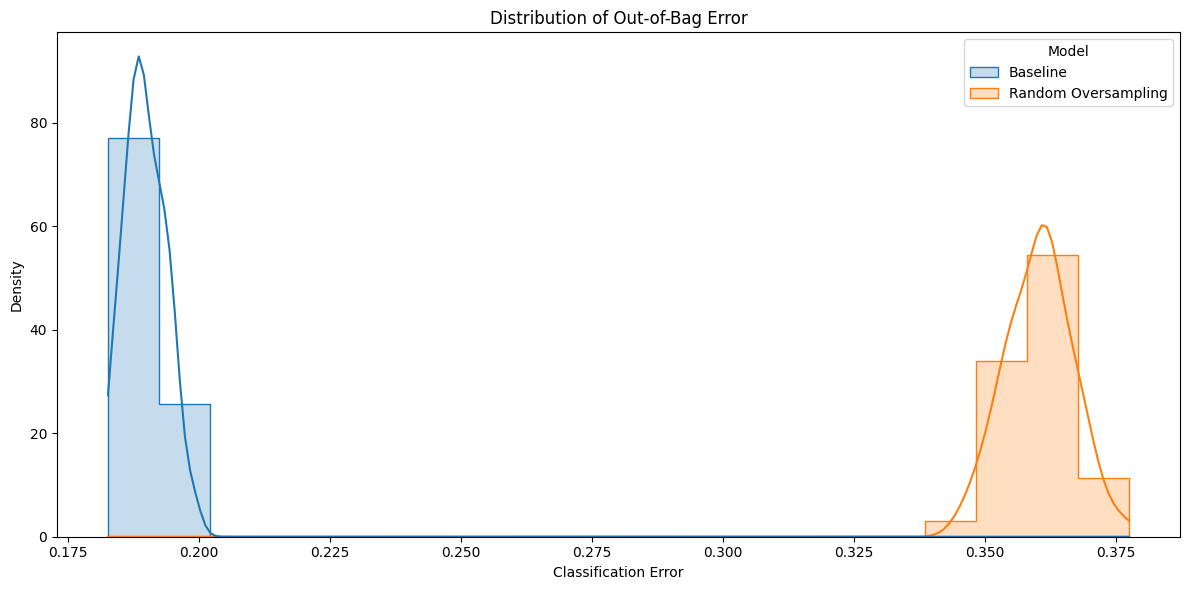

In [51]:
# Out-of-bag error distribution

plt.figure(figsize=(12, 6))

sns.histplot(
    data=bootstrap_results_df,
    x='OOB_Error',
    hue='Model',
    bins=20,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Distribution of Out-of-Bag Error')
plt.xlabel('Classification Error')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

In [52]:
paired_results = bootstrap_results_df.pivot(
    index='Iteration',
    columns='Model',
    values=bootstrap_metrics
)

paired_summary = []
paired_differences = {}

for metric in bootstrap_metrics:

    differences = (
        paired_results[metric]['Random Oversampling']
        -
        paired_results[metric]['Baseline']
    )

    paired_differences[metric] = differences

    if metric == 'OOB_Error':
        wins = (differences < 0).mean()
    else:
        wins = (differences > 0).mean()

    paired_summary.append({
        'Metric': metric,
        'Mean Difference': differences.mean(),
        'SD Difference': differences.std(ddof=1),
        '2.5th Percentile':
            differences.quantile(0.025),
        '97.5th Percentile':
            differences.quantile(0.975),
        'Candidate Win Rate (%)': wins * 100
    })

paired_summary_df = pd.DataFrame(
    paired_summary
)

display(paired_summary_df.round(4))

,Metric,Mean Difference,SD Difference,2.5th Percentile,97.5th Percentile,Candidate Win Rate (%)
0,Accuracy,-0.1706,0.0082,-0.1857,-0.1560,0.0
1,Precision,-0.2000,0.0360,-0.2710,-0.1335,0.0
2,Recall,0.5862,0.0188,0.5552,0.6255,100.0
3,F1,0.2945,0.0174,0.2636,0.3346,100.0
4,ROC_AUC,-0.0006,0.0009,-0.0022,0.0011,27.0
5,Average_Precision,-0.0011,0.0017,-0.0043,0.0021,28.0
6,Balanced_Accuracy,0.1194,0.0076,0.1050,0.1353,100.0
7,OOB_Error,0.1706,0.0082,0.1560,0.1857,0.0


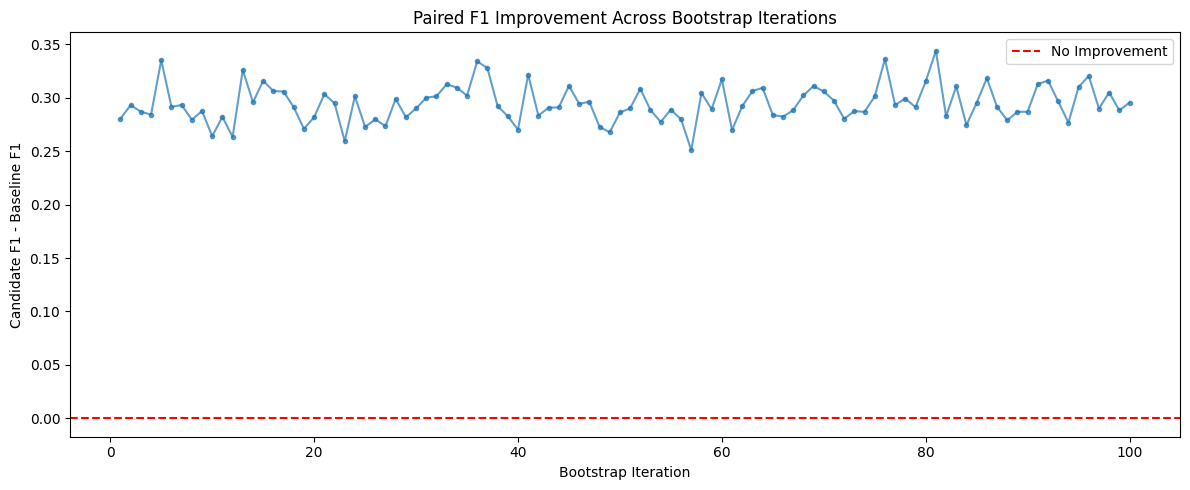

In [53]:
plt.figure(figsize=(12, 5))

plt.plot(
    paired_differences['F1'].index,
    paired_differences['F1'].values,
    marker='.',
    alpha=0.7
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    label='No Improvement'
)

plt.title('Paired F1 Improvement Across Bootstrap Iterations')
plt.xlabel('Bootstrap Iteration')
plt.ylabel('Candidate F1 - Baseline F1')
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# Identify unused development observations

unused_train_indices = X_train.index.difference(
    X_exp.index
)

# Select an independent development evaluation sample

ci_indices = (
    pd.Series(unused_train_indices)
    .sample(
        n=2000,
        random_state=RANDOM_STATE
    )
    .to_numpy()
)

X_ci = X_train.loc[ci_indices]
y_ci = y_train.loc[ci_indices]

# Confirm no overlap

assert len(
    X_ci.index.intersection(X_exp.index)
) == 0

assert len(
    X_ci.index.intersection(X_test.index)
) == 0

# Fit candidate model on experimental training data

ci_model = clone(bootstrap_model)

ci_model.fit(X_exp, y_exp)

ci_probabilities = ci_model.predict_proba(
    X_ci
)[:, 1]

ci_predictions = (
    ci_probabilities >= 0.5
).astype(int)

print("Model training records:", len(X_exp))
print("CI evaluation records:", len(X_ci))
print("CI evaluation default rate:",
      round(y_ci.mean() * 100, 2), "%")

display(
    pd.DataFrame([
        evaluate_bootstrap_metrics(
            y_ci,
            ci_probabilities
        )
    ]).round(4)
)

Model training records: 20000
CI evaluation records: 2000
CI evaluation default rate: 18.1 %


,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,OOB_Error
0,0.64,0.2859,0.6602,0.399,0.7121,0.3658,0.6479,0.36


In [55]:
# Define metric functions for paired bootstrapping

ci_metric_functions = {

    'Accuracy':
        lambda y, p: accuracy_score(
            y, p >= 0.5
        ),

    'Precision':
        lambda y, p: precision_score(
            y, p >= 0.5,
            zero_division=0
        ),

    'Recall':
        lambda y, p: recall_score(
            y, p >= 0.5,
            zero_division=0
        ),

    'F1':
        lambda y, p: f1_score(
            y, p >= 0.5,
            zero_division=0
        ),

    'ROC_AUC':
        lambda y, p: roc_auc_score(
            y, p
        ),

    'Average_Precision':
        lambda y, p: average_precision_score(
            y, p
        ),

    'Balanced_Accuracy':
        lambda y, p: balanced_accuracy_score(
            y, p >= 0.5
        ),

    'Classification_Error':
        lambda y, p: 1 - accuracy_score(
            y, p >= 0.5
        )
}

confidence_interval_results = []

y_ci_array = y_ci.to_numpy()

for metric_name, metric_function in tqdm(
    ci_metric_functions.items(),
    desc="Confidence intervals"
):

    point_estimate = metric_function(
        y_ci_array,
        ci_probabilities
    )

    for method in ['percentile', 'BCa']:

        # Capture warnings, including degenerate intervals

        with warnings.catch_warnings(record=True) as caught:

            warnings.simplefilter('always')

            result = bootstrap(
                data=(
                    y_ci_array,
                    ci_probabilities
                ),

                statistic=metric_function,

                paired=True,
                vectorized=False,

                n_resamples=N_CI_RESAMPLES,

                confidence_level=CONFIDENCE_LEVEL,

                method=method,

                batch=100,

                rng=np.random.default_rng(
                    RANDOM_STATE
                )
            )

        lower = result.confidence_interval.low
        upper = result.confidence_interval.high

        confidence_interval_results.append({
            'Metric': metric_name,
            'Method': method,
            'Point Estimate': point_estimate,
            'Lower 95% CI': lower,
            'Upper 95% CI': upper,
            'CI Width': upper - lower,
            'Bootstrap Standard Error':
                result.standard_error,
            'Warnings': '; '.join(
                str(w.message) for w in caught
            )
        })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_results
)

display(confidence_intervals_df.round(4))

Confidence intervals:   0%|          | 0/8 [00:00<?, ?it/s]

,Metric,Method,Point Estimate,Lower 95% CI,Upper 95% CI,CI Width,Bootstrap Standard Error,Warnings
0,Accuracy,percentile,0.6400,0.6195,0.6610,0.0415,0.0106,
1,Accuracy,BCa,0.6400,0.6185,0.6600,0.0415,0.0106,
2,Precision,percentile,0.2859,0.2573,0.3153,0.0581,0.0153,
3,Precision,BCa,0.2859,0.2579,0.3158,0.0579,0.0153,
4,Recall,percentile,0.6602,0.6131,0.7088,0.0957,0.0248,
5,Recall,BCa,0.6602,0.6138,0.7094,0.0955,0.0248,
6,F1,percentile,0.3990,0.3644,0.4327,0.0682,0.0175,
7,F1,BCa,0.3990,0.3659,0.4338,0.0679,0.0175,
8,ROC_AUC,percentile,0.7121,0.6815,0.7408,0.0592,0.0152,
9,ROC_AUC,BCa,0.7121,0.6821,0.7412,0.0591,0.0152,


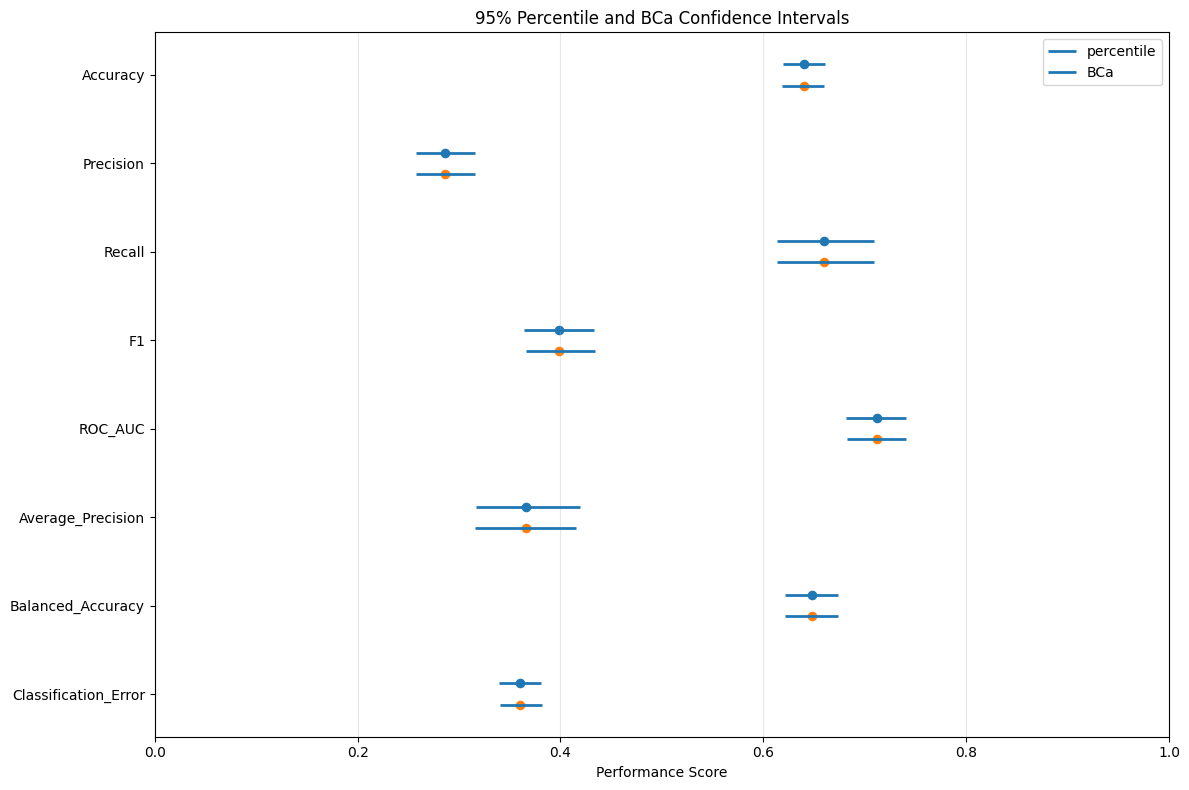

In [56]:
ci_plot = confidence_intervals_df.copy()

metrics = list(ci_metric_functions.keys())

fig, ax = plt.subplots(figsize=(12, 8))

positions = np.arange(len(metrics))

for method, offset in [
    ('percentile', -0.12),
    ('BCa', 0.12)
]:

    subset = (
        ci_plot[
            ci_plot['Method'] == method
        ]
        .set_index('Metric')
        .reindex(metrics)
    )

    y_position = positions + offset

    ax.hlines(
        y=y_position,
        xmin=subset['Lower 95% CI'],
        xmax=subset['Upper 95% CI'],
        linewidth=2,
        label=method
    )

    ax.scatter(
        subset['Point Estimate'],
        y_position,
        s=35
    )

ax.set_yticks(positions)
ax.set_yticklabels(metrics)

ax.set_xlabel('Performance Score')
ax.set_title(
    '95% Percentile and BCa Confidence Intervals'
)

ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.legend()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
ci_comparison_df = (
    confidence_intervals_df.pivot(
        index='Metric',
        columns='Method',
        values=[
            'Lower 95% CI',
            'Upper 95% CI',
            'CI Width'
        ]
    )
)

display(ci_comparison_df.round(4))

print("\nBCa confidence intervals:")

display(
    confidence_intervals_df[
        confidence_intervals_df['Method'] == 'BCa'
    ][[
        'Metric',
        'Point Estimate',
        'Lower 95% CI',
        'Upper 95% CI',
        'CI Width'
    ]].round(4)
)

print("\nConfidence interval warnings:")

display(
    confidence_intervals_df[
        confidence_intervals_df['Warnings'] != ''
    ][['Metric', 'Method', 'Warnings']]
)

Lower 95% CI            Upper 95% CI            CI Width  \
Method                        BCa percentile          BCa percentile      BCa   
Metric                                                                          
Accuracy                   0.6185     0.6195       0.6600     0.6610   0.0415   
Average_Precision          0.3157     0.3171       0.4158     0.4192   0.1001   
Balanced_Accuracy          0.6211     0.6213       0.6736     0.6738   0.0524   
Classification_Error       0.3400     0.3390       0.3815     0.3805   0.0415   
F1                         0.3659     0.3644       0.4338     0.4327   0.0679   
Precision                  0.2579     0.2573       0.3158     0.3153   0.0579   
ROC_AUC                    0.6821     0.6815       0.7412     0.7408   0.0591   
Recall                     0.6138     0.6131       0.7094     0.7088   0.0955   

                                 
Method               percentile  
Metric                           
Accuracy                 0.0415  
Average_Precision        0.1021  
Balanced_Accuracy        0.0525  
Classification_Error     0.0415  
F1                       0.0682  
Precision                0.0581  
ROC_AUC                  0.0592  
Recall                   0.0957


BCa confidence intervals:


,Metric,Point Estimate,Lower 95% CI,Upper 95% CI,CI Width
1,Accuracy,0.6400,0.6185,0.6600,0.0415
3,Precision,0.2859,0.2579,0.3158,0.0579
5,Recall,0.6602,0.6138,0.7094,0.0955
7,F1,0.3990,0.3659,0.4338,0.0679
9,ROC_AUC,0.7121,0.6821,0.7412,0.0591
11,Average_Precision,0.3658,0.3157,0.4158,0.1001
13,Balanced_Accuracy,0.6479,0.6211,0.6736,0.0524
15,Classification_Error,0.3600,0.3400,0.3815,0.0415



Confidence interval warnings:


,Metric,Method,Warnings


## Step 7: Error Analysis and Final Model Evaluation

This section evaluates alternative classification models,
investigates model errors, and identifies an appropriate
classification threshold for credit risk assessment.

Logistic Regression, Random Forest, and XGBoost are compared
using consistent cross-validation procedures.

The analysis includes:

- Comparative model performance
- Learning curves and bias-variance analysis
- Chronological model validation
- Probability calibration
- Decision threshold optimization
- Confusion matrices
- Probability residual analysis
- False positive and false negative analysis
- Independent chronological holdout evaluation

The final model and decision threshold are selected using
development data before evaluating the 2015 holdout dataset.

In [58]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    roc_curve,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.model_selection import learning_curve
from sklearn.calibration import calibration_curve

# Candidate models

candidate_models = {

    'Logistic Regression - Baseline':
        clone(resampling_pipelines['Baseline']),

    'Logistic Regression - Oversampling':
        clone(resampling_pipelines['Random Oversampling']),

    'Logistic Regression - Class Weighting':
        clone(resampling_pipelines['Class Weighting']),

    'Random Forest': Pipeline([
        ('preprocessor', clone(preprocessor)),

        ('classifier', RandomForestClassifier(
            n_estimators=150,
            max_depth=12,
            min_samples_leaf=10,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ]),

    'XGBoost': Pipeline([
        ('preprocessor', clone(preprocessor)),

        ('classifier', XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric='logloss',
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ])
}

print("Candidate models initialized:")

for name in candidate_models:
    print(name)

Candidate models initialized:
Logistic Regression - Baseline
Logistic Regression - Oversampling
Logistic Regression - Class Weighting
Random Forest
XGBoost


In [59]:
%pip install xgboost

In [60]:
model_comparison_results = []

for name, pipeline in candidate_models.items():

    print(f"Evaluating: {name}")

    start_time = time.time()

    scores = cross_validate(
        clone(pipeline),
        X_exp,
        y_exp,
        cv=resampling_cv,
        scoring=resampling_scoring,
        return_train_score=True,
        n_jobs=2,
        error_score='raise'
    )

    result = {'Model': name}

    for metric in resampling_scoring:

        result[metric] = scores[
            f'test_{metric}'
        ].mean()

        result[f'{metric}_SD'] = scores[
            f'test_{metric}'
        ].std(ddof=1)

    result['Train_ROC_AUC'] = scores[
        'train_ROC_AUC'
    ].mean()

    result['ROC_AUC_Gap'] = (
        result['Train_ROC_AUC'] -
        result['ROC_AUC']
    )

    result['Execution Time (s)'] = (
        time.time() - start_time
    )

    model_comparison_results.append(result)

model_comparison_df = pd.DataFrame(
    model_comparison_results
).sort_values(
    'Average_Precision',
    ascending=False
)

display(model_comparison_df.round(4))

Evaluating: Logistic Regression - Baseline
Evaluating: Logistic Regression - Oversampling
Evaluating: Logistic Regression - Class Weighting
Evaluating: Random Forest
Evaluating: XGBoost


,Model,Accuracy,Accuracy_SD,Precision,Precision_SD,Recall,Recall_SD,F1,F1_SD,ROC_AUC,ROC_AUC_SD,Average_Precision,Average_Precision_SD,Balanced_Accuracy,Balanced_Accuracy_SD,Train_ROC_AUC,ROC_AUC_Gap,Execution Time (s)
4,XGBoost,0.8111,0.0021,0.5191,0.0406,0.0648,0.0100,0.1151,0.0166,0.7034,0.0043,0.3578,0.0066,0.5254,0.0048,0.8007,0.0972,4.8862
0,Logistic Regression - Baseline,0.8107,0.0020,0.5134,0.0512,0.0574,0.0132,0.1030,0.0219,0.7046,0.0061,0.3555,0.0085,0.5223,0.0059,0.7129,0.0083,5.2859
2,Logistic Regression - Class Weighting,0.6395,0.0084,0.2968,0.0054,0.6556,0.0076,0.4085,0.0050,0.7044,0.0063,0.3552,0.0085,0.6456,0.0046,0.7130,0.0086,2.7094
1,Logistic Regression - Oversampling,0.6411,0.0077,0.2981,0.0056,0.6564,0.0062,0.4100,0.0057,0.7042,0.0063,0.3549,0.0083,0.6470,0.0053,0.7125,0.0083,2.9747
3,Random Forest,0.7152,0.0065,0.3358,0.0096,0.5103,0.0098,0.4050,0.0100,0.7035,0.0084,0.3540,0.0104,0.6368,0.0077,0.8690,0.1655,20.2021


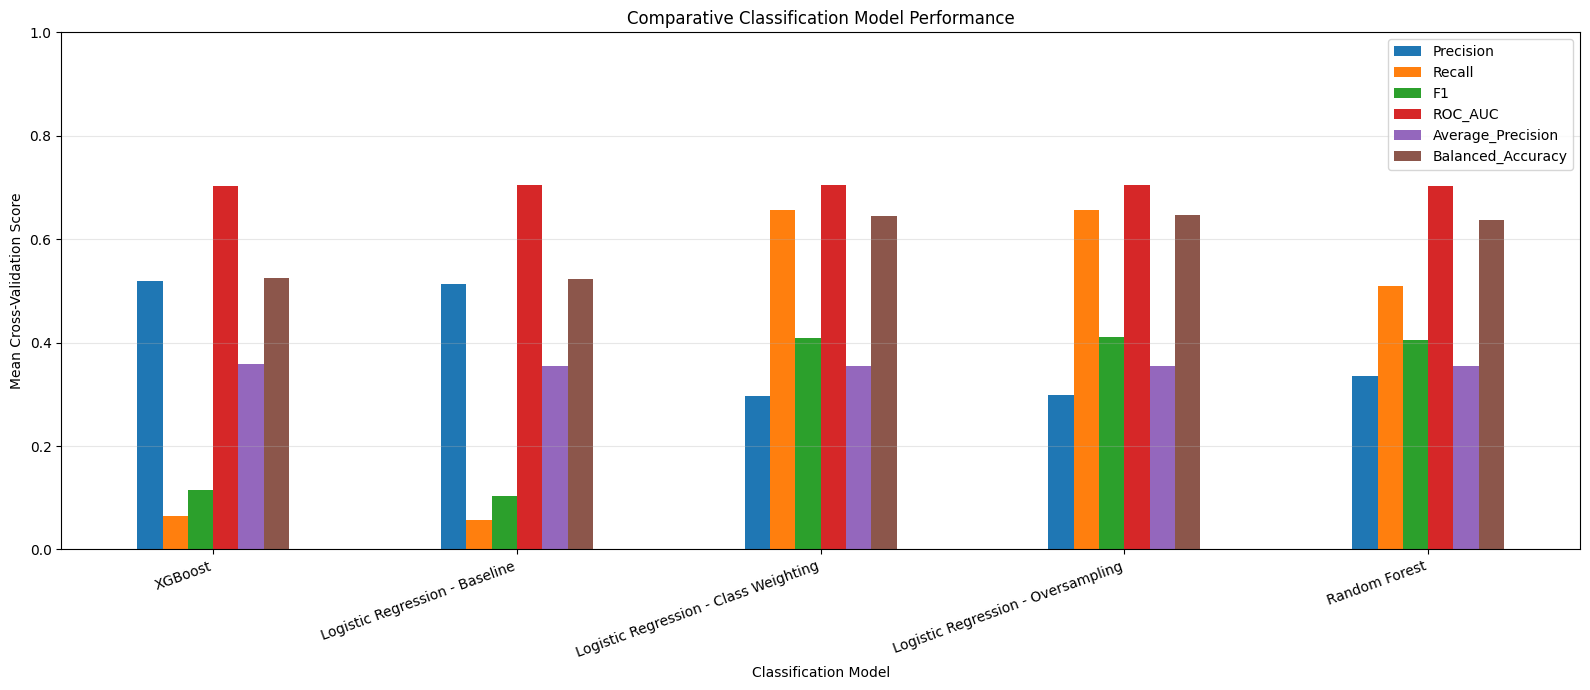

In [61]:
model_comparison_df.set_index('Model')[
    [
        'Precision',
        'Recall',
        'F1',
        'ROC_AUC',
        'Average_Precision',
        'Balanced_Accuracy'
    ]
].plot(
    kind='bar',
    figsize=(16, 7)
)

plt.title('Comparative Classification Model Performance')
plt.ylabel('Mean Cross-Validation Score')
plt.xlabel('Classification Model')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
temporal_model_results = []

for name, pipeline in candidate_models.items():

    print(f"Chronological evaluation: {name}")

    for fold, (train_months, val_months) in enumerate(
        tscv.split(unique_months), 1
    ):

        training_periods = unique_months[train_months]
        validation_periods = unique_months[val_months]

        train_idx = np.flatnonzero(
            months.isin(training_periods)
        )

        val_idx = np.flatnonzero(
            months.isin(validation_periods)
        )

        if (
            y_time.iloc[train_idx].nunique() < 2 or
            y_time.iloc[val_idx].nunique() < 2
        ):
            continue

        model = clone(pipeline)

        model.fit(
            X_time.iloc[train_idx],
            y_time.iloc[train_idx]
        )

        probabilities = model.predict_proba(
            X_time.iloc[val_idx]
        )[:, 1]

        result = evaluate_bootstrap_metrics(
            y_time.iloc[val_idx],
            probabilities
        )

        result.update({
            'Model': name,
            'Fold': fold,
            'Validation Start':
                str(validation_periods[0]),
            'Validation End':
                str(validation_periods[-1]),
            'Validation Records': len(val_idx)
        })

        temporal_model_results.append(result)

temporal_model_df = pd.DataFrame(
    temporal_model_results
).rename(columns={
    'OOB_Error': 'Classification_Error'
})

temporal_summary_df = (
    temporal_model_df.groupby('Model')[
        [
            'Recall',
            'F1',
            'ROC_AUC',
            'Average_Precision',
            'Balanced_Accuracy'
        ]
    ].mean()
    .sort_values(
        'Average_Precision',
        ascending=False
    )
)

display(temporal_model_df.round(4))
display(temporal_summary_df.round(4))

selected_model_name = (
    temporal_summary_df.index[0]
)

selected_pipeline = clone(
    candidate_models[selected_model_name]
)

print("\nSelected model:", selected_model_name)

Chronological evaluation: Logistic Regression - Baseline
Chronological evaluation: Logistic Regression - Oversampling
Chronological evaluation: Logistic Regression - Class Weighting
Chronological evaluation: Random Forest
Chronological evaluation: XGBoost


,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Classification_Error,Model,Fold,Validation Start,Validation End,Validation Records
0,0.8631,0.0000,0.0000,0.0000,0.5135,0.1365,0.4991,0.1369,Logistic Regression - Baseline,1,2009-03,2010-04,621
1,0.8507,0.3333,0.0047,0.0093,0.6938,0.2663,0.5015,0.1493,Logistic Regression - Baseline,2,2010-05,2011-06,1427
2,0.8352,0.5125,0.0755,0.1316,0.6911,0.3338,0.5306,0.1648,Logistic Regression - Baseline,3,2011-07,2012-08,3283
3,0.8056,0.4637,0.0614,0.1084,0.6267,0.2964,0.5222,0.1944,Logistic Regression - Baseline,4,2012-09,2013-10,7023
4,0.7862,0.4726,0.0710,0.1235,0.6949,0.3649,0.5248,0.2138,Logistic Regression - Baseline,5,2013-11,2014-12,7437
5,0.7649,0.1395,0.1429,0.1412,0.5116,0.1356,0.5025,0.2351,Logistic Regression - Oversampling,1,2009-03,2010-04,621
6,0.6405,0.2308,0.6085,0.3346,0.6925,0.2624,0.6273,0.3595,Logistic Regression - Oversampling,2,2010-05,2011-06,1427
7,0.6330,0.2552,0.6354,0.3641,0.6895,0.3343,0.6339,0.3670,Logistic Regression - Oversampling,3,2011-07,2012-08,3283
8,0.6640,0.2730,0.4482,0.3393,0.6155,0.2911,0.5818,0.3360,Logistic Regression - Oversampling,4,2012-09,2013-10,7023
9,0.6048,0.3090,0.6988,0.4285,0.6942,0.3630,0.6392,0.3952,Logistic Regression - Oversampling,5,2013-11,2014-12,7437


,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy
Model,,,,,
Logistic Regression - Baseline,0.0425,0.0746,0.6440,0.2796,0.5157
Random Forest,0.2957,0.2649,0.6660,0.2789,0.5748
Logistic Regression - Class Weighting,0.5075,0.3201,0.6409,0.2775,0.5955
Logistic Regression - Oversampling,0.5067,0.3216,0.6407,0.2773,0.5969
XGBoost,0.0486,0.0833,0.6474,0.2642,0.5156



Selected model: Logistic Regression - Baseline


,Training Size,Training ROC-AUC,Validation ROC-AUC,Training SD,Validation SD,Generalization Gap
0,1600,0.7263,0.6868,0.0193,0.0053,0.0395
1,4480,0.7230,0.6983,0.0051,0.0063,0.0247
2,7359,0.7198,0.7000,0.0053,0.0050,0.0198
3,10240,0.7166,0.7017,0.0060,0.0055,0.0150
4,13120,0.7139,0.7031,0.0029,0.0051,0.0108
5,16000,0.7129,0.7046,0.0011,0.0055,0.0083


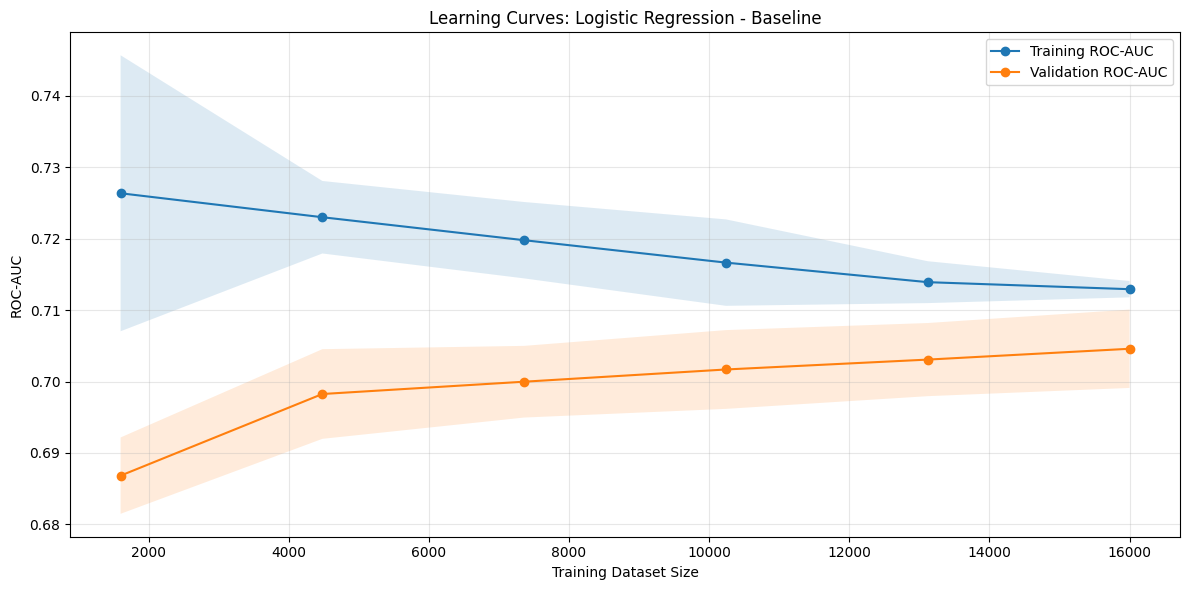

In [63]:
train_sizes, train_scores, val_scores = learning_curve(

    clone(selected_pipeline),

    X_exp,
    y_exp,

    cv=resampling_cv,

    train_sizes=np.linspace(0.1, 1.0, 6),

    scoring='roc_auc',

    shuffle=True,
    random_state=RANDOM_STATE,

    n_jobs=2,
    error_score='raise'
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

learning_results_df = pd.DataFrame({
    'Training Size': train_sizes,
    'Training ROC-AUC': train_mean,
    'Validation ROC-AUC': val_mean,
    'Training SD': train_std,
    'Validation SD': val_std,
    'Generalization Gap': train_mean - val_mean
})

display(learning_results_df.round(4))

plt.figure(figsize=(12, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training ROC-AUC'
)

plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation ROC-AUC'
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

plt.title(f'Learning Curves: {selected_model_name}')
plt.xlabel('Training Dataset Size')
plt.ylabel('ROC-AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
from scipy.special import logit

reserved_indices = (
    X_exp.index.union(X_ci.index)
)

available_indices = (
    X_train.index.difference(reserved_indices)
)

rng = np.random.default_rng(RANDOM_STATE)

reserved_sample = rng.choice(
    available_indices.to_numpy(),
    size=20000,
    replace=False
)

calibration_indices = reserved_sample[:10000]
threshold_indices = reserved_sample[10000:]

X_cal = X_train.loc[calibration_indices]
y_cal = y_train.loc[calibration_indices]

X_threshold = X_train.loc[threshold_indices]
y_threshold = y_train.loc[threshold_indices]

# Exclude evaluation and calibration samples from fitting

final_reserved = (
    X_cal.index
    .union(X_threshold.index)
    .union(X_ci.index)
)

final_train_indices = (
    X_train.index.difference(final_reserved)
)

X_final_train = X_train.loc[final_train_indices]
y_final_train = y_train.loc[final_train_indices]

assert len(
    X_final_train.index.intersection(X_cal.index)
) == 0

assert len(
    X_final_train.index.intersection(X_threshold.index)
) == 0

assert len(
    X_final_train.index.intersection(X_test.index)
) == 0

print("Final model training size:", len(X_final_train))
print("Calibration sample:", len(X_cal))
print("Threshold selection sample:", len(X_threshold))
print("Final test sample:", len(X_test))

Final model training size: 206046
Calibration sample: 10000
Threshold selection sample: 10000
Final test sample: 26144


In [65]:
final_model = clone(selected_pipeline)

final_model.fit(
    X_final_train,
    y_final_train
)

# Raw calibration probabilities

cal_raw_prob = final_model.predict_proba(
    X_cal
)[:, 1]

# Sigmoid calibration using an independent sample

def probability_to_logit(probabilities):

    probabilities = np.clip(
        probabilities,
        1e-6,
        1 - 1e-6
    )

    return logit(probabilities).reshape(-1, 1)


calibrator = LogisticRegression(
    C=1e6,
    max_iter=1000,
    random_state=RANDOM_STATE
)

calibrator.fit(
    probability_to_logit(cal_raw_prob),
    y_cal
)

def calibrated_predict(model, X):

    raw_prob = model.predict_proba(X)[:, 1]

    return calibrator.predict_proba(
        probability_to_logit(raw_prob)
    )[:, 1]


# Evaluate calibration on separate threshold data

threshold_raw_prob = final_model.predict_proba(
    X_threshold
)[:, 1]

threshold_cal_prob = calibrated_predict(
    final_model,
    X_threshold
)

calibration_results_df = pd.DataFrame({

    'Method': [
        'Before Calibration',
        'After Calibration'
    ],

    'Brier Score': [
        brier_score_loss(
            y_threshold,
            threshold_raw_prob
        ),
        brier_score_loss(
            y_threshold,
            threshold_cal_prob
        )
    ],

    'Mean Predicted Default Probability': [
        threshold_raw_prob.mean(),
        threshold_cal_prob.mean()
    ],

    'Observed Default Rate': [
        y_threshold.mean(),
        y_threshold.mean()
    ]
})

display(calibration_results_df.round(4))

,Method,Brier Score,Mean Predicted Default Probability,Observed Default Rate
0,Before Calibration,0.1383,0.1884,0.1875
1,After Calibration,0.1383,0.1899,0.1875


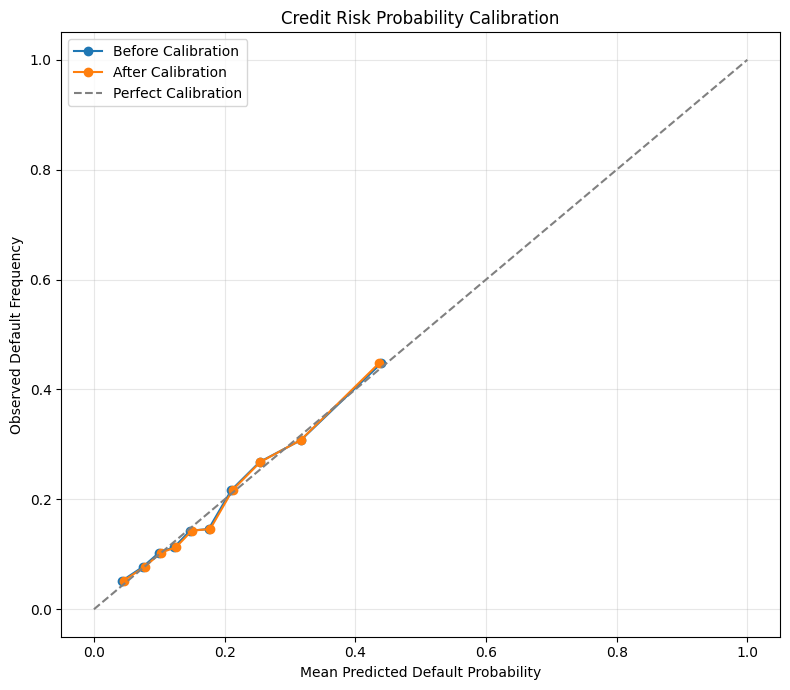

In [66]:
plt.figure(figsize=(8, 7))

for name, probabilities in [

    ('Before Calibration', threshold_raw_prob),
    ('After Calibration', threshold_cal_prob)

]:

    observed, predicted = calibration_curve(
        y_threshold,
        probabilities,
        n_bins=10,
        strategy='quantile'
    )

    plt.plot(
        predicted,
        observed,
        marker='o',
        label=name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Perfect Calibration'
)

plt.xlabel('Mean Predicted Default Probability')
plt.ylabel('Observed Default Frequency')
plt.title('Credit Risk Probability Calibration')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
threshold_results = []

for threshold in np.linspace(0, 1, 201):

    predictions = (
        threshold_cal_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_threshold,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({

        'Threshold': threshold,

        'Precision': precision_score(
            y_threshold,
            predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_threshold,
            predictions,
            zero_division=0
        ),

        'F1': f1_score(
            y_threshold,
            predictions,
            zero_division=0
        ),

        'Balanced_Accuracy':
            balanced_accuracy_score(
                y_threshold,
                predictions
            ),

        'False Positives': fp,
        'False Negatives': fn,

        'Relative Cost':
            5 * fn + fp
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

best_f1_row = threshold_results_df.loc[
    threshold_results_df['F1'].idxmax()
]

best_cost_row = threshold_results_df.loc[
    threshold_results_df['Relative Cost'].idxmin()
]

print("Optimal F1 threshold:")
display(best_f1_row.to_frame().T.round(4))

print("\nMinimum cost threshold:")
display(best_cost_row.to_frame().T.round(4))

# Select business cost-based threshold

FINAL_THRESHOLD = float(
    best_cost_row['Threshold']
)

print("\nSelected classification threshold:",
      FINAL_THRESHOLD)

Optimal F1 threshold:


,Threshold,Precision,Recall,F1,Balanced_Accuracy,False Positives,False Negatives,Relative Cost
44,0.22,0.332,0.5829,0.4231,0.6561,2199.0,782.0,6109.0



Minimum cost threshold:


,Threshold,Precision,Recall,F1,Balanced_Accuracy,False Positives,False Negatives,Relative Cost
38,0.19,0.3072,0.6752,0.4223,0.6619,2855.0,609.0,5900.0



Selected classification threshold: 0.19


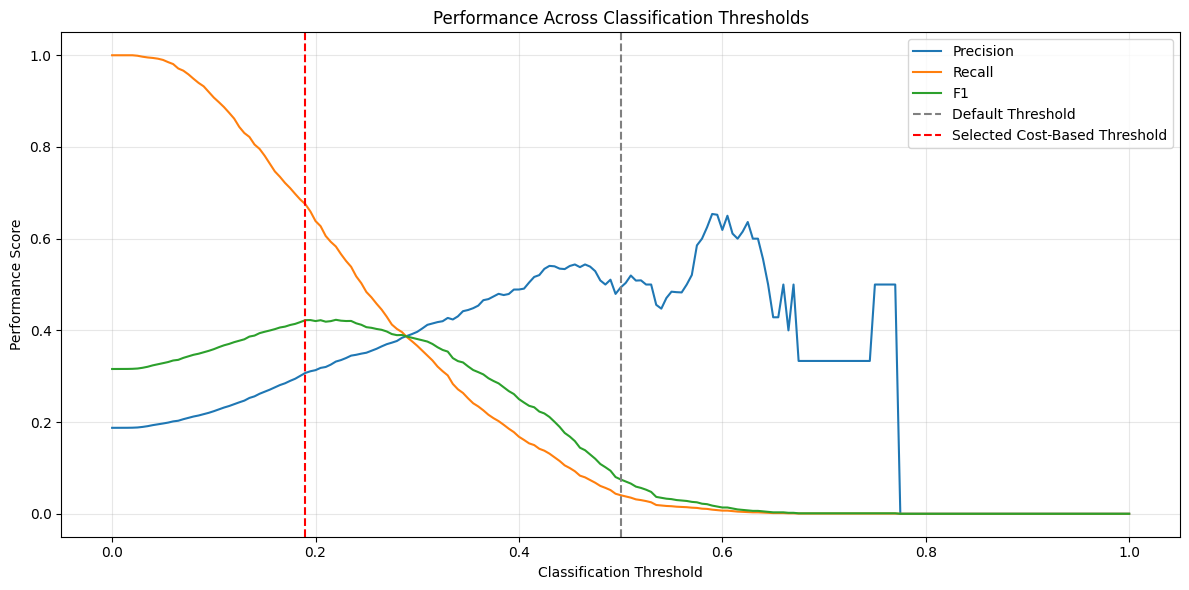

In [68]:
plt.figure(figsize=(12, 6))

for metric in ['Precision', 'Recall', 'F1']:

    plt.plot(
        threshold_results_df['Threshold'],
        threshold_results_df[metric],
        label=metric
    )

plt.axvline(
    x=0.5,
    linestyle='--',
    color='gray',
    label='Default Threshold'
)

plt.axvline(
    x=FINAL_THRESHOLD,
    linestyle='--',
    color='red',
    label='Selected Cost-Based Threshold'
)

plt.title('Performance Across Classification Thresholds')
plt.xlabel('Classification Threshold')
plt.ylabel('Performance Score')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [69]:
cost_sensitivity = []

for fn_cost in [1, 2, 5, 10, 20]:

    costs = (

        fn_cost *
        threshold_results_df['False Negatives']

        + threshold_results_df['False Positives']
    )

    best_row = threshold_results_df.loc[
        costs.idxmin()
    ]

    cost_sensitivity.append({

        'FN to FP Cost Ratio': f'{fn_cost}:1',

        'Optimal Threshold':
            best_row['Threshold'],

        'Recall': best_row['Recall'],

        'Precision': best_row['Precision'],

        'F1': best_row['F1'],

        'Minimum Relative Cost': costs.min()
    })

cost_sensitivity_df = pd.DataFrame(
    cost_sensitivity
)

display(cost_sensitivity_df.round(4))

,FN to FP Cost Ratio,Optimal Threshold,Recall,Precision,F1,Minimum Relative Cost
0,1:1,0.43,0.1312,0.5407,0.2112,1838
1,2:1,0.33,0.3019,0.4272,0.3538,3377
2,5:1,0.19,0.6752,0.3072,0.4223,5900
3,10:1,0.08,0.9488,0.2121,0.3467,7567
4,20:1,0.05,0.9899,0.1969,0.3285,7949


In [70]:
# Evaluate the final model

test_raw_prob = final_model.predict_proba(
    X_test
)[:, 1]

test_cal_prob = calibrated_predict(
    final_model,
    X_test
)

test_predictions = (
    test_cal_prob >= FINAL_THRESHOLD
).astype(int)

# Evaluate original baseline for reference

reference_model = clone(
    candidate_models['Logistic Regression - Baseline']
)

reference_model.fit(
    X_final_train,
    y_final_train
)

reference_prob = reference_model.predict_proba(
    X_test
)[:, 1]

final_evaluation_results = []

evaluation_configurations = [

    (
        'Original Logistic Regression Baseline',
        reference_prob,
        0.5
    ),

    (
        'Selected Model - Raw Probability',
        test_raw_prob,
        0.5
    ),

    (
        'Selected Model - Calibrated',
        test_cal_prob,
        0.5
    ),

    (
        'Final Optimized Model',
        test_cal_prob,
        FINAL_THRESHOLD
    )
]

for name, probabilities, threshold in (
    evaluation_configurations
):

    result = evaluate_bootstrap_metrics(
        y_test,
        probabilities,
        threshold=threshold
    )

    result['Classification_Error'] = result.pop(
        'OOB_Error'
    )

    result['Model'] = name
    result['Threshold'] = threshold

    result['Brier_Score'] = brier_score_loss(
        y_test,
        probabilities
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    result['True Negatives'] = tn
    result['False Positives'] = fp
    result['False Negatives'] = fn
    result['True Positives'] = tp

    result['Relative Error Cost'] = (
        5 * fn + fp
    )

    final_evaluation_results.append(result)

final_evaluation_df = pd.DataFrame(
    final_evaluation_results
)

display(final_evaluation_df.round(4))

print("\nFinal selected model:", selected_model_name)
print("Final threshold:", FINAL_THRESHOLD)

print("\nClassification Report:")

print(classification_report(
    y_test,
    test_predictions,
    target_names=['Non-Default', 'Default'],
    zero_division=0
))

,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Classification_Error,Model,Threshold,Brier_Score,True Negatives,False Positives,False Negatives,True Positives,Relative Error Cost
0,0.8685,0.3476,0.1000,0.1553,0.7059,0.2391,0.5371,0.1315,Original Logistic Regression Baseline,0.50,0.1099,22391,593,2844,316,14813
1,0.8685,0.3476,0.1000,0.1553,0.7059,0.2391,0.5371,0.1315,Selected Model - Raw Probability,0.50,0.1099,22391,593,2844,316,14813
2,0.8690,0.3439,0.0924,0.1457,0.7059,0.2391,0.5341,0.1310,Selected Model - Calibrated,0.50,0.1099,22427,557,2868,292,14897
3,0.5905,0.1892,0.7272,0.3003,0.7059,0.2391,0.6494,0.4095,Final Optimized Model,0.19,0.1099,13139,9845,862,2298,14155



Final selected model: Logistic Regression - Baseline
Final threshold: 0.19

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.94      0.57      0.71     22984
     Default       0.19      0.73      0.30      3160

    accuracy                           0.59     26144
   macro avg       0.56      0.65      0.51     26144
weighted avg       0.85      0.59      0.66     26144



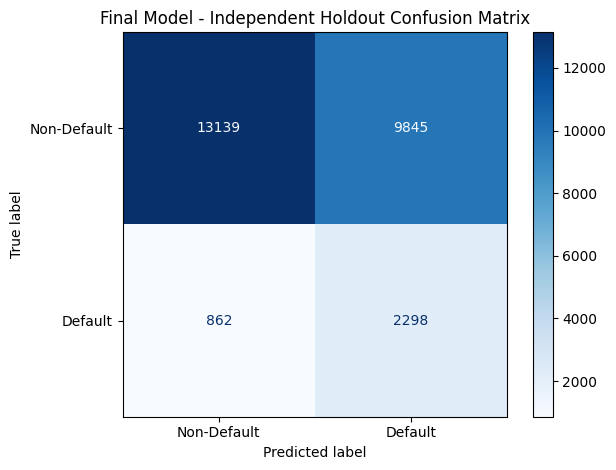

True Negatives: 13139
False Positives: 9845
False Negatives: 862
True Positives: 2298

False Positive Rate: 0.4283
False Negative Rate: 0.2728


In [71]:
cm_final = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=['Non-Default', 'Default']
).plot(
    cmap='Blues',
    values_format='d'
)

plt.title('Final Model - Independent Holdout Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_final.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nFalse Positive Rate:",
      round(fp / (fp + tn), 4))

print("False Negative Rate:",
      round(fn / (fn + tp), 4))

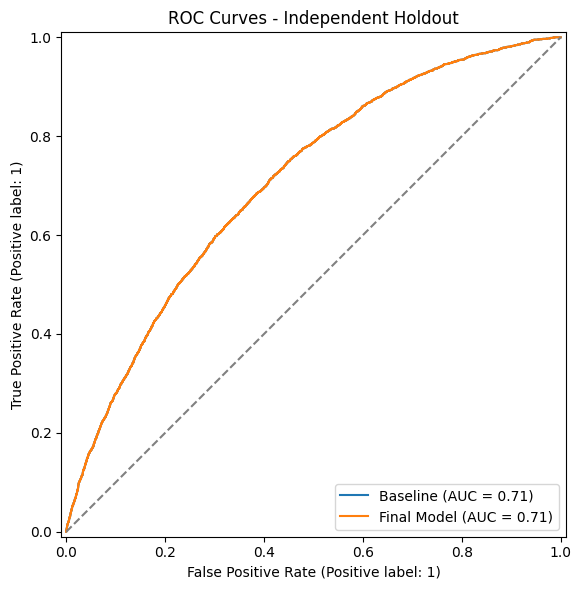

In [72]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    reference_prob,
    name='Baseline',
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    test_cal_prob,
    name='Final Model',
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.title('ROC Curves - Independent Holdout')
plt.tight_layout()
plt.show()

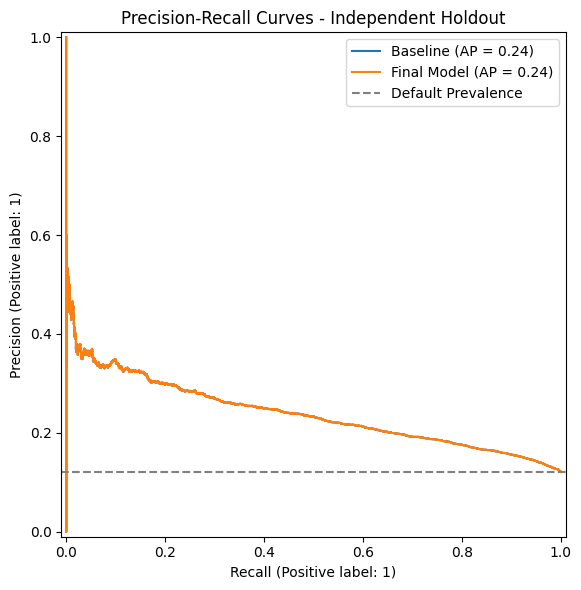

In [73]:
fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    reference_prob,
    name='Baseline',
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_cal_prob,
    name='Final Model',
    ax=ax
)

ax.axhline(
    y=y_test.mean(),
    linestyle='--',
    color='gray',
    label='Default Prevalence'
)

plt.title('Precision-Recall Curves - Independent Holdout')
plt.legend()
plt.tight_layout()
plt.show()

In [74]:
error_analysis_df = X_test.copy()

error_analysis_df['Actual'] = y_test.to_numpy()

error_analysis_df['Predicted'] = test_predictions

error_analysis_df['Default_Probability'] = (
    test_cal_prob
)

error_analysis_df['Probability_Residual'] = (

    error_analysis_df['Actual'] -
    error_analysis_df['Default_Probability']
)

error_analysis_df['Error_Type'] = np.select(

    [

        (error_analysis_df['Actual'] == 0) &
        (error_analysis_df['Predicted'] == 0),

        (error_analysis_df['Actual'] == 0) &
        (error_analysis_df['Predicted'] == 1),

        (error_analysis_df['Actual'] == 1) &
        (error_analysis_df['Predicted'] == 0),

        (error_analysis_df['Actual'] == 1) &
        (error_analysis_df['Predicted'] == 1)

    ],

    [
        'True Negative',
        'False Positive',
        'False Negative',
        'True Positive'
    ],

    default='Unknown'
)

display(
    error_analysis_df['Error_Type'].value_counts()
)

error_features = [
    'loan_amnt',
    'annual_inc',
    'int_rate',
    'dti',
    'revol_util',
    'credit_history_years',
    'loan_to_income',
    'installment_to_income'
]

error_profile_df = (
    error_analysis_df.groupby('Error_Type')[
        error_features
    ].median()
)

display(error_profile_df.round(3))

,count
Error_Type,
True Negative,13139
False Positive,9845
True Positive,2298
False Negative,862


,loan_amnt,annual_inc,int_rate,dti,revol_util,credit_history_years,loan_to_income,installment_to_income
Error_Type,,,,,,,,
False Negative,10700.0,75000.0,11.99,16.22,51.35,15.209,0.153,0.057
False Positive,15000.0,56000.0,16.55,20.90,55.00,13.999,0.269,0.093
True Negative,10150.0,75000.0,10.99,14.66,43.10,15.335,0.147,0.054
True Positive,14400.0,52000.0,17.57,23.24,60.00,13.495,0.286,0.099


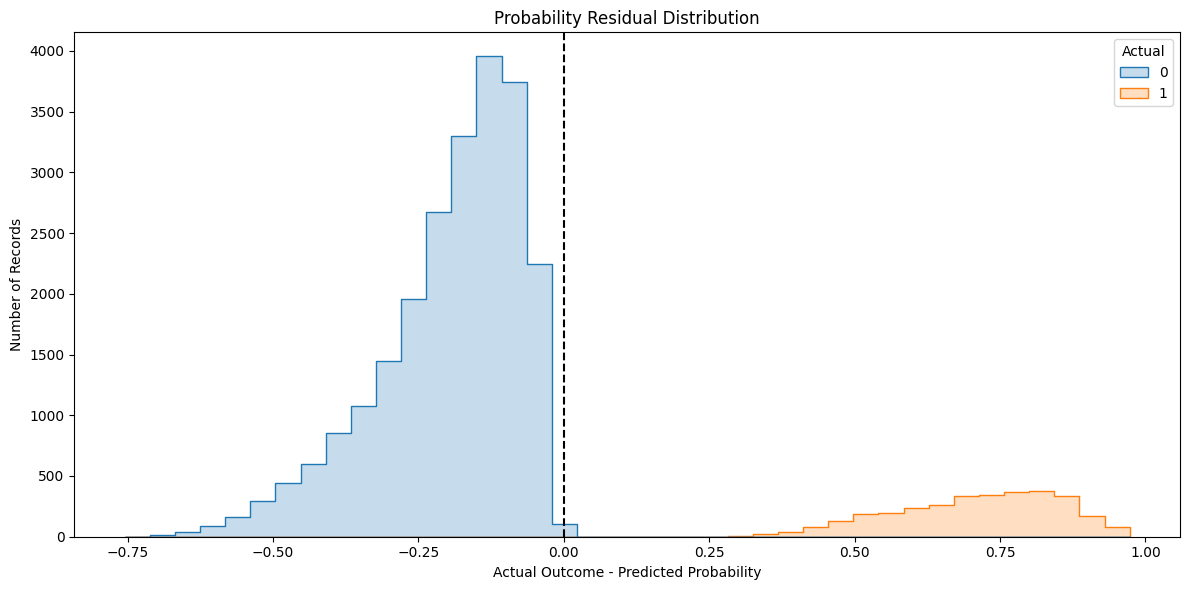

In [75]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=error_analysis_df,
    x='Probability_Residual',
    hue='Actual',
    bins=40,
    element='step',
    common_norm=False
)

plt.axvline(
    0,
    color='black',
    linestyle='--'
)

plt.title('Probability Residual Distribution')
plt.xlabel('Actual Outcome - Predicted Probability')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

,Records,Observed_Default_Rate,Predicted_Default_Rate,Mean_Residual
Risk_Decile,,,,
"(0.00366, 0.0661]",2615,0.0249,0.0463,-0.0214
"(0.0661, 0.0963]",2614,0.0371,0.0819,-0.0448
"(0.0963, 0.123]",2614,0.0566,0.1093,-0.0527
"(0.123, 0.149]",2615,0.0826,0.1358,-0.0532
"(0.149, 0.178]",2614,0.0880,0.1632,-0.0752
"(0.178, 0.213]",2614,0.1209,0.1953,-0.0744
"(0.213, 0.255]",2615,0.1369,0.2327,-0.0958
"(0.255, 0.311]",2614,0.1653,0.2811,-0.1159
"(0.311, 0.398]",2614,0.2108,0.3504,-0.1396


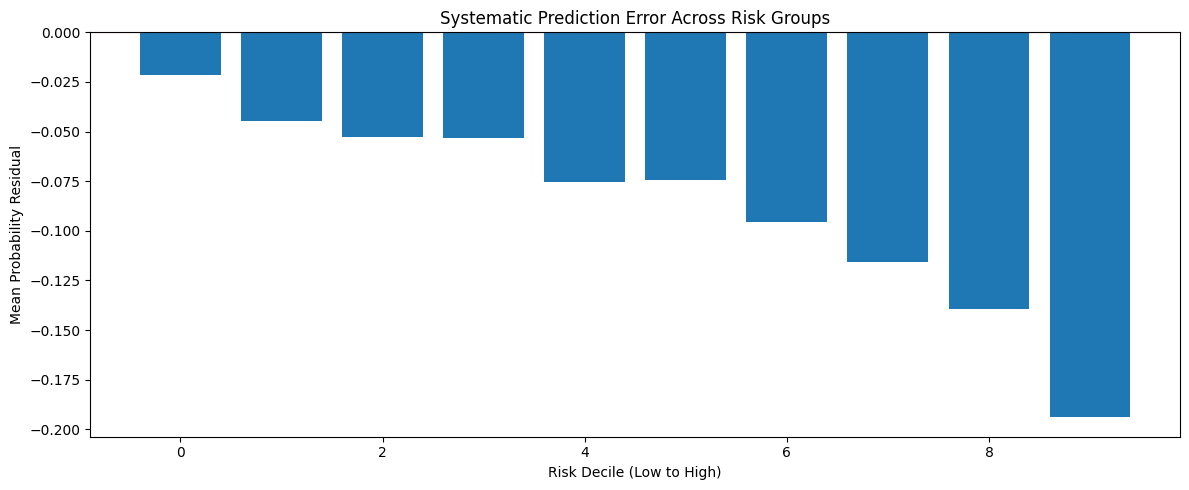

In [76]:
# Examine average residuals across risk score groups

error_analysis_df['Risk_Decile'] = pd.qcut(
    error_analysis_df['Default_Probability'],
    q=10,
    duplicates='drop'
)

residual_summary_df = (
    error_analysis_df.groupby(
        'Risk_Decile',
        observed=True
    ).agg(

        Records=('Actual', 'size'),

        Observed_Default_Rate=('Actual', 'mean'),

        Predicted_Default_Rate=(
            'Default_Probability', 'mean'
        ),

        Mean_Residual=(
            'Probability_Residual', 'mean'
        )
    )
)

display(residual_summary_df.round(4))

plt.figure(figsize=(12, 5))

plt.bar(
    range(len(residual_summary_df)),
    residual_summary_df['Mean_Residual']
)

plt.axhline(
    0,
    linestyle='--',
    color='red'
)

plt.xlabel('Risk Decile (Low to High)')
plt.ylabel('Mean Probability Residual')
plt.title('Systematic Prediction Error Across Risk Groups')
plt.tight_layout()
plt.show()

In [77]:
grade_results = []

for grade, group in error_analysis_df.groupby('grade'):

    actual = group['Actual']
    predicted = group['Predicted']

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    grade_results.append({

        'Grade': grade,

        'Records': len(group),

        'Observed Default Rate':
            actual.mean(),

        'Mean Predicted Risk':
            group['Default_Probability'].mean(),

        'Accuracy':
            accuracy_score(actual, predicted),

        'Precision':
            precision_score(
                actual,
                predicted,
                zero_division=0
            ),

        'Recall':
            recall_score(
                actual,
                predicted,
                zero_division=0
            ),

        'False Positive Rate':
            fp / (fp + tn)
            if fp + tn > 0 else np.nan,

        'False Negative Rate':
            fn / (fn + tp)
            if fn + tp > 0 else np.nan
    })

grade_results_df = pd.DataFrame(
    grade_results
)

display(grade_results_df.round(4))

,Grade,Records,Observed Default Rate,Mean Predicted Risk,Accuracy,Precision,Recall,False Positive Rate,False Negative Rate
0,A,3331,0.0321,0.0615,0.9667,0.0000,0.0000,0.0012,1.0000
1,B,5995,0.0686,0.1230,0.8679,0.1505,0.1995,0.0829,0.8005
2,C,7683,0.1071,0.1948,0.5659,0.1444,0.6197,0.4405,0.3803
3,D,4769,0.1757,0.2776,0.3263,0.1931,0.8914,0.7942,0.1086
4,E,2978,0.2079,0.3573,0.2445,0.2119,0.9693,0.9457,0.0307
5,F,1090,0.2670,0.4192,0.2835,0.2702,0.9897,0.9737,0.0103
6,G,298,0.2383,0.4828,0.2450,0.2399,1.0000,0.9912,0.0000


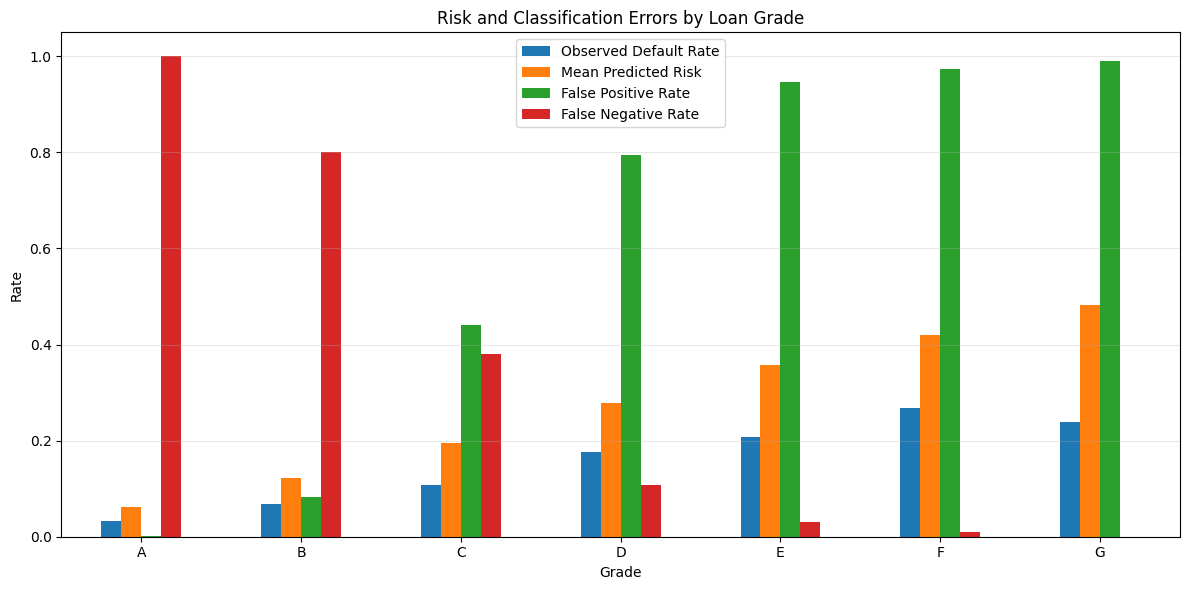

In [78]:
grade_results_df.set_index('Grade')[
    [
        'Observed Default Rate',
        'Mean Predicted Risk',
        'False Positive Rate',
        'False Negative Rate'
    ]
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Risk and Classification Errors by Loan Grade')
plt.ylabel('Rate')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [79]:
business_results_df = final_evaluation_df[
    [
        'Model',
        'True Positives',
        'False Positives',
        'False Negatives',
        'Relative Error Cost'
    ]
].copy()

reference_cost = (
    business_results_df.iloc[0][
        'Relative Error Cost'
    ]
)

business_results_df['Cost Reduction (%)'] = (

    (reference_cost -
     business_results_df['Relative Error Cost'])

    / reference_cost * 100
)

display(business_results_df.round(3))

print("\nFINAL RESEARCH RESULTS")

display(
    final_evaluation_df[
        [
            'Model',
            'Threshold',
            'Accuracy',
            'Precision',
            'Recall',
            'F1',
            'ROC_AUC',
            'Average_Precision',
            'Balanced_Accuracy',
            'Brier_Score'
        ]
    ].round(4)
)

,Model,True Positives,False Positives,False Negatives,Relative Error Cost,Cost Reduction (%)
0,Original Logistic Regression Baseline,316,593,2844,14813,0.000
1,Selected Model - Raw Probability,316,593,2844,14813,0.000
2,Selected Model - Calibrated,292,557,2868,14897,-0.567
3,Final Optimized Model,2298,9845,862,14155,4.442



FINAL RESEARCH RESULTS


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Brier_Score
0,Original Logistic Regression Baseline,0.50,0.8685,0.3476,0.1000,0.1553,0.7059,0.2391,0.5371,0.1099
1,Selected Model - Raw Probability,0.50,0.8685,0.3476,0.1000,0.1553,0.7059,0.2391,0.5371,0.1099
2,Selected Model - Calibrated,0.50,0.8690,0.3439,0.0924,0.1457,0.7059,0.2391,0.5341,0.1099
3,Final Optimized Model,0.19,0.5905,0.1892,0.7272,0.3003,0.7059,0.2391,0.6494,0.1099


## Step 8: Research Findings, Interpretation, and Conclusion

### Research Summary

This research developed and evaluated a credit risk assessment model using historical LendingClub loan data. The original dataset contained 887,379 observations and 74 variables. After excluding unresolved loan outcomes and selecting appropriate predictors, 254,190 observations were retained for binary classification.

The study investigated feature engineering, feature selection, cross-validation, class imbalance, bootstrap uncertainty estimation, probability calibration, and cost-sensitive classification.

### Cross-Validation Findings

Stratified five-fold cross-validation provided the most stable ROC-AUC estimates among the randomized validation strategies evaluated. It maintained consistent class distributions and achieved a mean ROC-AUC of 0.7046 with a standard deviation of 0.0061.

Chronological validation produced lower performance estimates, highlighting the importance of evaluating predictive models against later observations rather than relying exclusively on randomized partitions.

### Resampling Findings

Random Oversampling achieved the highest observed F1-score of 0.4100 among the resampling experiments, improving recall from 5.74% to 65.64%. SMOTE-ENN achieved the highest recall but introduced a substantial number of false positives.

Bootstrap analysis confirmed that Random Oversampling consistently improved recall, F1-score, and balanced accuracy relative to the baseline at the 0.5 classification threshold. However, resampling did not materially improve ROC-AUC or average precision.

### Final Model Selection

Logistic Regression with LASSO feature selection was selected based on chronological average precision. Although Random Forest and XGBoost provided competitive performance, both demonstrated larger training-validation performance gaps.

Decision threshold optimization identified 0.19 as the preferred classification threshold under an assumed false negative to false positive cost ratio of 5:1.

### Independent Holdout Evaluation

The final model achieved a recall of 72.72%, an F1-score of 0.3003, a ROC-AUC of 0.7059, and balanced accuracy of 64.94% on the independent 2015 holdout dataset.

Compared with the original baseline, the optimized model identified 1,982 additional defaults and reduced missed defaults from 2,844 to 862. However, false positives increased substantially, resulting in a precision of 18.92%.

The hypothetical total classification error cost decreased by 4.44%.

### Error Analysis

False positives were the most common classification error in the final model. False negatives represented potentially more costly errors under the assumed business cost structure.

Probability residual analysis revealed systematic overestimation of default risk across all ten risk deciles in the holdout dataset. This suggests that calibration based on historical data may not remain reliable when borrower populations and loan outcome distributions change.

### Business Recommendations

The model should be considered a preliminary risk-screening tool rather than an autonomous lending decision system. High-risk predictions could support additional borrower assessment and human review.

Financial institutions should establish realistic error costs, monitor predictive performance over time, recalibrate probabilities using appropriately matured loan cohorts, and conduct demographic fairness assessments before deployment.

### Research Limitations

The study excluded unresolved loans, introducing potential selection and loan maturity bias. Detailed payment histories and FICO credit scores were unavailable. Computational constraints required smaller experimental samples for feature selection, cross-validation, and bootstrap analysis.

The chronological evaluation was retrospective because the availability dates of final loan outcomes were not explicitly established. The hypothetical error cost ratio does not represent verified financial losses.

The bootstrap confidence intervals were calculated for the Random Oversampling candidate rather than the final threshold-optimized model.

### Conclusion

The findings demonstrate that reliable credit risk assessment requires more than maximizing classification accuracy or adopting complex machine learning algorithms. Appropriate validation strategies, systematic error analysis, uncertainty estimation, and business-aligned decision thresholds are essential for developing dependable predictive models.

In this study, an interpretable Logistic Regression model with an optimized classification threshold provided a practical balance between default detection, computational efficiency, and model generalization. Nevertheless, further validation and calibration are necessary before the model can be considered suitable for real-world lending decisions.